# Bài tập 1 — Đặc trưng góc & Phân vùng ảnh

Môn Thị giác máy tính (121036) — Trường Đại học Giao thông Vận tải TP.HCM

**Nhóm:** M

| Người | Họ tên | MSSV | Phụ trách |
| --- | --- | --- | --- |
| 1 | | | Harris cổ điển, đo repeatability, kiểm chứng A1, A2, A4, ghép notebook |
| 2 | | | Harris–Laplace (A1), kiểm chứng A3, thí nghiệm A1 vs Harris |
| 3 | | | ANMS (A2), kiểm chứng A5, thí nghiệm A2 vs Harris |
| 4 | | | Region Growing cổ điển, `srg_step_frames`, `seed_sensitivity`, kiểm chứng B4, thí nghiệm SRG vs RG |
| 5 | | | Seeded Region Growing, kiểm chứng B1, B2, B3, B5, thí nghiệm lazy/frozen và đồng hạng |

**Cách chạy:** đặt notebook cùng cấp với thư mục `anh/` (có sẵn `anh/oxford/`), rồi chọn Restart & Run All. Toàn bộ notebook chạy khoảng 5 phút; phần lâu nhất là kiểm chứng A3 của Người 2 (khoảng 4 phút).

## 0. Thư viện, hằng số và hàm dùng chung

In [1]:
%matplotlib inline
import math
import os
import sys
import time
import heapq
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter          # chỉ dùng để làm mờ Gauss
from scipy.ndimage import label as nd_label        # chỉ dùng ở phần phân tích

plt.rcParams["figure.max_open_warning"] = 0

In [ ]:
import math
import os
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter          # chỉ dùng để làm mờ Gauss
from scipy.ndimage import label as nd_label        # chỉ dùng ở phần phân tích

# ---------------------------------------------------------------- hằng số
S_RATIO = 0.7                                   # sigma_d = S_RATIO * sigma_i
NB4 = [(-1, 0), (1, 0), (0, -1), (0, 1)]        # trên, dưới, trái, phải
NB8 = NB4 + [(-1, -1), (-1, 1), (1, -1), (1, 1)]


# ---------------------------------------------------------------- nạp ảnh
def load_gray(path):
    """Đọc ảnh xám, trả float64 trong [0, 1]."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Không đọc được ảnh: {path}")
    return img.astype(np.float64) / 255.0


# ---------------------------------------------------------------- phép biến đổi chuẩn
def make_scale(img, factor):
    """Đổi tỉ lệ ảnh bằng cv2.resize.

    -> (ảnh mới, transform). transform(row, col) của ảnh cũ -> (row, col) ở ảnh mới,
    theo quy ước tâm pixel của OpenCV.
    """
    H, W = img.shape
    new_h, new_w = int(round(H * factor)), int(round(W * factor))
    interp = cv2.INTER_LINEAR if factor >= 1 else cv2.INTER_AREA
    out = cv2.resize(img, (new_w, new_h), interpolation=interp)
    fy, fx = new_h / H, new_w / W

    def transform(r, c):
        r = np.asarray(r, dtype=np.float64)
        c = np.asarray(c, dtype=np.float64)
        return (r + 0.5) * fy - 0.5, (c + 0.5) * fx - 0.5

    return out, transform


def make_rotation(img, deg, fill=None):
    """Quay ảnh quanh tâm một góc deg (độ, dương = ngược chiều kim đồng hồ trên màn hình).

    Tự viết bằng numpy (ánh xạ ngược + nội suy song tuyến) vì cv2.warpAffine
    không có trong danh sách thư viện được phép. Ảnh mới giữ nguyên kích thước.
    Pixel rơi ra ngoài ảnh cũ được gán bằng `fill` (mặc định: trung vị của ảnh)
    để mép phần ảnh quay không tạo góc giả.

    -> (ảnh mới, transform). transform(row, col) của ảnh cũ -> (row, col) ở ảnh mới.
    """
    H, W = img.shape
    if fill is None:
        fill = float(np.median(img))
    t = math.radians(deg)
    cs, sn = math.cos(t), math.sin(t)
    cy, cx = (H - 1) / 2.0, (W - 1) / 2.0

    # Với mỗi pixel (y', x') của ảnh mới, tìm vị trí (y, x) tương ứng ở ảnh cũ.
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float64)
    dx, dy = xx - cx, yy - cy
    xs = cx + cs * dx - sn * dy
    ys = cy + sn * dx + cs * dy

    inside = (xs >= 0) & (xs <= W - 1) & (ys >= 0) & (ys <= H - 1)
    x0 = np.clip(np.floor(xs).astype(int), 0, W - 1)
    y0 = np.clip(np.floor(ys).astype(int), 0, H - 1)
    x1 = np.clip(x0 + 1, 0, W - 1)
    y1 = np.clip(y0 + 1, 0, H - 1)
    wx = xs - x0
    wy = ys - y0
    val = (img[y0, x0] * (1 - wx) * (1 - wy) + img[y0, x1] * wx * (1 - wy)
           + img[y1, x0] * (1 - wx) * wy + img[y1, x1] * wx * wy)
    out = np.where(inside, val, fill)

    def transform(r, c):
        r = np.asarray(r, dtype=np.float64)
        c = np.asarray(c, dtype=np.float64)
        dxa, dya = c - cx, r - cy
        x_new = cx + cs * dxa + sn * dya
        y_new = cy - sn * dxa + cs * dya
        return y_new, x_new

    return out, transform


# ---------------------------------------------------------------- bộ ảnh Oxford
OXFORD_DIR = os.path.join(os.getcwd(), "anh", "oxford")


def homography_transform(H):
    """Biến ma trận homography 3x3 (theo quy ước (x, y) = (col, row) của bộ Oxford)
    thành hàm transform(row, col) -> (row, col) dùng được cho repeatability.
    """
    H = np.asarray(H, dtype=np.float64)

    def transform(r, c):
        r = np.asarray(r, dtype=np.float64)
        c = np.asarray(c, dtype=np.float64)
        x = H[0, 0] * c + H[0, 1] * r + H[0, 2]
        y = H[1, 0] * c + H[1, 1] * r + H[1, 2]
        w = H[2, 0] * c + H[2, 1] * r + H[2, 2]
        return y / w, x / w

    return transform


def load_oxford(ten, k=1):
    """Đọc ảnh thứ k (1..6) của bộ Oxford `ten` (bark, bikes, boat, graf, leuven, trees, ubc, wall).

    Ảnh đã được đổi sang xám và thu nhỏ về cạnh dài 512 px.
    -> (ảnh, transform). transform(row, col) chiếu điểm từ ảnh 1 sang ảnh k
       (k = 1 thì là phép đồng nhất).
    """
    img = load_gray(os.path.join(OXFORD_DIR, ten, f"img{k}.png"))
    if k == 1:
        H = np.eye(3)
    else:
        H = np.loadtxt(os.path.join(OXFORD_DIR, ten, f"H1to{k}.txt"))
    return img, homography_transform(H)


# ---------------------------------------------------------------- phần B
def remap_labels(labels, perm):
    """Đổi nhãn i >= 0 thành perm[i]; pixel -1 giữ nguyên.

    Dùng khi so hai kết quả chạy với danh sách hạt giống bị đảo thứ tự.
    """
    perm = np.asarray(perm)
    out = labels.copy()
    m = labels >= 0
    out[m] = perm[labels[m]]
    return out


# ---------------------------------------------------------------- đo đạc
def grid_occupancy(points, img_shape, n_cells=8):
    """Tính tỷ lệ ô trong lưới có ít nhất một điểm.

    Chia ảnh thành lưới n_cells x n_cells, trả tỉ lệ ô có ít nhất một điểm.
    """
    pts = np.asarray(points, dtype=np.float64)
    if pts.size == 0:
        return 0.0
    H, W = img_shape[:2]
    gr = np.clip((pts[:, 0] * n_cells / H).astype(int), 0, n_cells - 1)
    gc = np.clip((pts[:, 1] * n_cells / W).astype(int), 0, n_cells - 1)
    return len(set(zip(gr.tolist(), gc.tolist()))) / float(n_cells * n_cells)


# ---------------------------------------------------------------- vẽ
def show_points(ax, img, pts, title="", color="r", circles=False):
    """Vẽ ảnh xám và các điểm. Cột 1 (col) là trục ngang.

    circles=True: pts có cột sigma (đầu ra harris_laplace), vẽ vòng tròn bán kính 2*sigma.
    """
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    pts = np.asarray(pts)
    if pts.size:
        if circles and pts.shape[1] >= 4:
            for r, c, s in pts[:, :3]:
                ax.add_patch(plt.Circle((c, r), 2 * s, color=color, fill=False, lw=0.8))
        else:
            ax.plot(pts[:, 1], pts[:, 0], "+", color=color, ms=7, mew=1.2)
    ax.set_title(title)
    ax.axis("off")


def show_labels(ax, labels, title=""):
    """Vẽ ảnh nhãn bằng tab20; pixel -1 hiển thị màu đen."""
    cmap = plt.get_cmap("tab20").copy()
    cmap.set_bad("black")
    ax.imshow(np.ma.masked_less(labels, 0), cmap=cmap, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")


def time_ms(fn, *args, repeat=3, **kwargs):
    """Chạy fn `repeat` lần, trả (kết quả, thời gian nhỏ nhất tính bằng ms)."""
    best = float("inf")
    out = None
    for _ in range(repeat):
        t0 = time.perf_counter()
        out = fn(*args, **kwargs)
        best = min(best, (time.perf_counter() - t0) * 1000)
    return out, best

# Phần A — Harris và hai biến thể

## A.1 Harris cổ điển (Người 1)

In [3]:
import math

import numpy as np
from scipy.ndimage import gaussian_filter


def gaussian_blur(img, sigma):
    """Làm mờ Gauss. Được phép gọi scipy.ndimage.gaussian_filter."""
    img = np.asarray(img, dtype=np.float64)
    if sigma <= 0:
        return img.copy()
    return gaussian_filter(img, sigma, mode="reflect")


def structure_tensor(img, sigma_i, sigma_d):
    """Ma trận mô-men bậc hai theo công thức (1), đã nhân sigma_d**2.
    sigma_d: độ mờ trước khi lấy đạo hàm.
    sigma_i: bán kính cửa sổ lấy trung bình các tích đạo hàm.
    -> (Mxx, Mxy, Myy), mỗi phần tử cùng kích thước ảnh.
    """
    L = gaussian_blur(img, sigma_d)
    Ly = np.gradient(L, axis=0)      # đạo hàm theo hàng (hướng y)
    Lx = np.gradient(L, axis=1)      # đạo hàm theo cột (hướng x)
    s2 = sigma_d ** 2                # chuẩn hóa theo tỉ lệ (Lindeberg)
    Mxx = s2 * gaussian_blur(Lx * Lx, sigma_i)
    Mxy = s2 * gaussian_blur(Lx * Ly, sigma_i)
    Myy = s2 * gaussian_blur(Ly * Ly, sigma_i)
    return Mxx, Mxy, Myy


def harris_response(img, sigma_i, sigma_d, k=0.04):
    """Đáp ứng R theo công thức (2). -> mảng float cùng kích thước ảnh."""
    Mxx, Mxy, Myy = structure_tensor(img, sigma_i, sigma_d)
    det = Mxx * Myy - Mxy ** 2
    tr = Mxx + Myy
    return det - k * tr ** 2


def nms_2d(response, window=3):
    """Cực đại địa phương trong cửa sổ window x window. -> mảng bool.

    Phá hòa theo thứ tự quét raster: khi hai pixel trong cùng cửa sổ có R bằng
    nhau tuyệt đối (hay gặp ở ảnh tổng hợp đối xứng như bàn cờ), chỉ pixel đứng
    trước theo thứ tự quét được giữ. Nhờ vậy mỗi đỉnh chỉ cho một điểm.
    """
    if window % 2 == 0 or window < 1:
        raise ValueError("window phải là số lẻ dương")
    R = np.asarray(response, dtype=np.float64)
    p = window // 2
    P = np.pad(R, p, mode="constant", constant_values=-np.inf)
    win = np.lib.stride_tricks.sliding_window_view(P, (window, window))

    # Vị trí trong cửa sổ đứng trước tâm theo thứ tự quét: hàng trên, hoặc cùng hàng bên trái.
    dr, dc = np.mgrid[-p:p + 1, -p:p + 1]
    earlier = (dr < 0) | ((dr == 0) & (dc < 0))
    later = (dr > 0) | ((dr == 0) & (dc > 0))

    max_earlier = np.where(earlier, win, -np.inf).max(axis=(2, 3))
    max_later = np.where(later, win, -np.inf).max(axis=(2, 3))
    return (R > max_earlier) & (R >= max_later)


def harris_classic(img, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.01):
    """Harris một tỉ lệ: R -> nms_2d -> ngưỡng tương đối theo max(R).
    -> mảng (N, 3): (row, col, response), sắp xếp giảm dần theo response.
    """
    R = harris_response(img, sigma_i, sigma_d, k)
    r_max = R.max()
    if not np.isfinite(r_max) or r_max <= 0:
        return np.zeros((0, 3))

    mask = nms_2d(R) & (R > thresh_rel * r_max) & (R > 0)

    # Bỏ vùng sát mép: ở đó đạo hàm bị méo do pad.
    m = int(math.ceil(3 * sigma_i))
    if m > 0:
        mask[:m, :] = False
        mask[-m:, :] = False
        mask[:, :m] = False
        mask[:, -m:] = False

    rows, cols = np.nonzero(mask)
    vals = R[rows, cols]
    order = np.argsort(-vals, kind="stable")
    pts = np.column_stack([rows, cols, vals]).astype(np.float64)
    return pts[order]


def repeatability(pts_a, pts_b, transform, img_shape, eps=3.0):
    """Tỉ lệ điểm của ảnh A tìm lại được trong ảnh B sau phép biến đổi.
    transform: hàm (row, col) của A -> (row, col) tương ứng ở B.
    Chỉ tính trên các điểm mà ảnh chiếu còn nằm trong B.
    -> số thực trong [0, 1].
    """
    A = np.asarray(pts_a, dtype=np.float64)
    B = np.asarray(pts_b, dtype=np.float64)
    if A.size == 0:
        return float("nan")
    A = A.reshape(len(A), -1)[:, :2]          # bỏ cột sigma/response
    r, c = transform(A[:, 0], A[:, 1])
    r = np.asarray(r, dtype=np.float64)
    c = np.asarray(c, dtype=np.float64)

    H, W = img_shape[:2]
    inside = (r >= 0) & (r < H) & (c >= 0) & (c < W)
    n_valid = int(inside.sum())
    if n_valid == 0:
        return float("nan")
    if B.size == 0:
        return 0.0

    P = np.column_stack([r[inside], c[inside]])
    Q = B.reshape(len(B), -1)[:, :2]
    matched = 0
    for s in range(0, len(P), 1000):          # tính theo khối để không tràn bộ nhớ
        d2 = ((P[s:s + 1000, None, :] - Q[None, :, :]) ** 2).sum(axis=2)
        matched += int((d2.min(axis=1) <= eps ** 2).sum())
    return matched / n_valid

## A.2 Biến thể A1 — Harris–Laplace (Người 2)

In [4]:
import math

import numpy as np
from scipy.ndimage import gaussian_filter



def scale_pyramid(sigma0=1.2, xi=1.2, n_levels=10):
    """Tháp tỉ lệ hình học: sigma_n = sigma0 * xi^n, n = 0..n_levels-1."""
    return np.array([sigma0 * (xi ** n) for n in range(n_levels)], dtype=np.float64)


def log_normalized(img, sigma):
    """Laplacian-of-Gaussian chuẩn hóa Lindeberg tại tỉ lệ sigma.

    Trả về sigma^2 * |Lxx + Lyy|, dùng np.gradient bậc hai.
    """
    L = gaussian_filter(img, sigma, mode="reflect")
    Lxx = np.gradient(np.gradient(L, axis=1), axis=1)
    Lyy = np.gradient(np.gradient(L, axis=0), axis=0)
    return (sigma ** 2) * np.abs(Lxx + Lyy)


def harris_laplace(img, sigmas, k=0.04, thresh_rel=0.01, log_thresh=0.0):
    """Harris–Laplace detector đa tỉ lệ.

    Bước 1 — ứng viên Harris: với mỗi tầng sigma_n, tính R, lấy cực đại
    địa phương NMS, lọc theo ngưỡng tương đối thresh_rel * R_max_toàn_cục
    và bỏ vùng mép ceil(3*sigma_n) pixel.

    Bước 2 — chọn tỉ lệ bằng LoG: chỉ giữ ứng viên là cực đại địa phương
    của log_stack theo trục tháp (giữa tầng n-1 và n+1) và vượt log_thresh.

    Trả về ndarray float64 shape (N, 4): [row, col, sigma, response],
    sắp xếp giảm dần theo response. Nếu rỗng trả về zeros((0, 4)).
    """
    n_levels = len(sigmas)

    r_maps = []
    cand_masks = []
    for sigma_n in sigmas:
        R = harris_response(img, sigma_i=sigma_n, sigma_d=S_RATIO * sigma_n, k=k)
        r_maps.append(R)
        cand_masks.append(nms_2d(R, window=3) & (R > 0))

    r_global_max = max(R.max() for R in r_maps)
    if not np.isfinite(r_global_max) or r_global_max <= 0:
        return np.zeros((0, 4), dtype=np.float64)

    threshold = thresh_rel * r_global_max
    step1 = []
    for n, sigma_n in enumerate(sigmas):
        R = r_maps[n]
        mask = cand_masks[n] & (R > threshold)
        m = int(math.ceil(3 * sigma_n))
        mask[:m, :] = False
        mask[-m:, :] = False
        mask[:, :m] = False
        mask[:, -m:] = False
        rows, cols = np.nonzero(mask)
        for r, c in zip(rows, cols):
            step1.append((n, r, c, float(R[r, c])))

    if not step1:
        return np.zeros((0, 4), dtype=np.float64)

    log_stack = np.stack([log_normalized(img, s) for s in sigmas], axis=0)

    final = []
    for n, r, c, resp in step1:
        if n == 0 or n == n_levels - 1:
            continue
        v = log_stack[n, r, c]
        if v > log_stack[n - 1, r, c] and v > log_stack[n + 1, r, c] and v > log_thresh:
            final.append((r, c, sigmas[n], resp))

    if not final:
        return np.zeros((0, 4), dtype=np.float64)

    pts = np.array(final, dtype=np.float64)
    return pts[np.argsort(-pts[:, 3], kind="stable")]


def _harris_laplace_debug(img, sigmas, k=0.04, thresh_rel=0.01, log_thresh=0.0):
    """Như harris_laplace nhưng trả thêm số ứng viên mỗi bước.

    Trả về (pts, n_step1, n_step2) — dùng cho thống kê thí nghiệm.
    """
    n_levels = len(sigmas)

    r_maps = []
    cand_masks = []
    for sigma_n in sigmas:
        R = harris_response(img, sigma_i=sigma_n, sigma_d=S_RATIO * sigma_n, k=k)
        r_maps.append(R)
        cand_masks.append(nms_2d(R, window=3) & (R > 0))

    r_global_max = max(R.max() for R in r_maps)
    if not np.isfinite(r_global_max) or r_global_max <= 0:
        return np.zeros((0, 4), dtype=np.float64), 0, 0

    threshold = thresh_rel * r_global_max
    step1 = []
    for n, sigma_n in enumerate(sigmas):
        R = r_maps[n]
        mask = cand_masks[n] & (R > threshold)
        m = int(math.ceil(3 * sigma_n))
        mask[:m, :] = False
        mask[-m:, :] = False
        mask[:, :m] = False
        mask[:, -m:] = False
        rows, cols = np.nonzero(mask)
        for r, c in zip(rows, cols):
            step1.append((n, r, c, float(R[r, c])))

    n_step1 = len(step1)
    log_stack = np.stack([log_normalized(img, s) for s in sigmas], axis=0)

    final = []
    for n, r, c, resp in step1:
        if n == 0 or n == n_levels - 1:
            continue
        v = log_stack[n, r, c]
        if v > log_stack[n - 1, r, c] and v > log_stack[n + 1, r, c] and v > log_thresh:
            final.append((r, c, sigmas[n], resp))

    n_step2 = len(final)
    if not final:
        return np.zeros((0, 4), dtype=np.float64), n_step1, n_step2

    pts = np.array(final, dtype=np.float64)
    return pts[np.argsort(-pts[:, 3], kind="stable")], n_step1, n_step2

## A.3 Biến thể A2 — Adaptive non-maximal suppression (Người 3)

In [5]:
import numpy as np


def top_n(points, n_keep):
    """Đường cơ sở: N điểm có response lớn nhất.
    -> (n_keep, 3), sắp xếp giảm dần theo response.
    """
    pts = np.asarray(points, dtype=np.float64).reshape(-1, 3)
    if len(pts) == 0:
        return np.zeros((0, 3))
    order = np.argsort(-pts[:, 2], kind="stable")
    return pts[order][:n_keep]


def _anms_radii(points, c_robust=0.9, chunk=1000):
    """Bán kính ức chế r_i theo công thức (4).

    r_i = khoảng cách nhỏ nhất từ điểm i tới các điểm j có f_i < c_robust * f_j.
    Không có j nào như vậy thì r_i = inf (điểm mạnh nhất luôn như vậy).
    Tính theo khối `chunk` điểm để không tạo ma trận N x N quá lớn.
    """
    pts = np.asarray(points, dtype=np.float64).reshape(-1, 3)
    N = len(pts)
    r = np.full(N, np.inf)
    if N == 0:
        return r
    xy = pts[:, :2]
    f = pts[:, 2]
    for s in range(0, N, chunk):
        e = min(s + chunk, N)
        d2 = ((xy[s:e, None, :] - xy[None, :, :]) ** 2).sum(axis=2)       # (khối, N)
        manh_hon = f[s:e, None] < c_robust * f[None, :]                   # j mạnh hơn i đáng kể
        d2 = np.where(manh_hon, d2, np.inf)
        r[s:e] = np.sqrt(d2.min(axis=1))
    return r


def anms(points, n_keep, c_robust=0.9):
    """Adaptive non-maximal suppression (Brown, Szeliski & Winder 2005).
    -> (n_keep, 3) gồm row, col, response, sắp xếp giảm dần theo r.
       Khi r bằng nhau, điểm có response lớn hơn đứng trước.
    """
    pts = np.asarray(points, dtype=np.float64).reshape(-1, 3)
    if len(pts) == 0:
        return np.zeros((0, 3))
    pts = pts[np.argsort(-pts[:, 2], kind="stable")]      # sắp theo response trước
    r = _anms_radii(pts, c_robust)
    order = np.argsort(-r, kind="stable")                  # r giảm dần, giữ thứ tự response khi bằng nhau
    return pts[order][:n_keep]

## A.4 Kiểm chứng A1, A2, A4 (Người 1)

**Prompt AI** — Người 1 · công cụ: Antigravity IDE · ngày 9/11/2026
> Viết phần import thư viện, khởi tạo đường dẫn thư mục ket_qua/ và anh/,
> cùng các hàm tạo ảnh tổng hợp (bàn cờ 8×8 ô 32px và cảnh đa giác lồi)
> để phục vụ kiểm chứng A1, A2, A4.

In [6]:
import os


import cv2
import matplotlib.pyplot as plt
import numpy as np


HERE = os.getcwd()
OUT = os.path.join(HERE, "ket_qua")
ANH = os.path.join(HERE, "anh")
os.makedirs(OUT, exist_ok=True)
os.makedirs(ANH, exist_ok=True)


# ---------------------------------------------------------------- ảnh thử
def tao_ban_co(n_o=8, canh=32):
    """Bàn cờ n_o x n_o ô, mỗi ô `canh` px, giá trị 0 và 1, phủ kín ảnh."""
    idx = np.arange(n_o * canh) // canh
    return ((idx[:, None] + idx[None, :]) % 2).astype(np.float64)


def _da_giac(H, W, dinh):
    """Mặt nạ của đa giác lồi, đỉnh (row, col) theo một chiều."""
    yy, xx = np.mgrid[0:H, 0:W]
    m = np.ones((H, W), dtype=bool)
    n = len(dinh)
    s0 = None
    for i in range(n):
        (r1, c1), (r2, c2) = dinh[i], dinh[(i + 1) % n]
        cross = (c2 - c1) * (yy - r1) - (r2 - r1) * (xx - c1)
        if s0 is None:
            s0 = np.sign((c2 - c1) * (dinh[(i + 2) % n][0] - r1) - (r2 - r1) * (dinh[(i + 2) % n][1] - c1))
        m &= (cross * s0) >= 0
    return m


def tao_canh_tong_hop(H=320, W=320):
    """Nền xám 0.5 với vài hình đặc, đặt gọn trong vòng tròn nội tiếp để quay không bị cắt."""
    img = np.full((H, W), 0.5)
    img[_da_giac(H, W, [(60, 70), (60, 130), (120, 130), (120, 70)])] = 0.1     # hình vuông
    img[_da_giac(H, W, [(180, 60), (180, 150), (220, 150), (220, 60)])] = 0.9   # hình chữ nhật
    img[_da_giac(H, W, [(90, 200), (150, 260), (150, 180)])] = 0.2              # tam giác
    img[_da_giac(H, W, [(195, 220), (230, 255), (265, 220), (230, 185)])] = 0.85  # hình thoi
    return img


def luu_anh(img, ten):
    cv2.imwrite(os.path.join(ANH, ten), np.round(np.clip(img, 0, 1) * 255).astype(np.uint8))

#### KIỂM CHỨNG A1 — Bàn cờ tổng hợp

**Prompt AI** — Người 1 · công cụ: Antigravity IDE · ngày 9/11/2026
> Phát hiện góc trên ảnh bàn cờ bằng harris_classic, đối chiếu với 49
> giao điểm chuẩn (sai số <= 1 px), in thống kê ĐẠT/CHƯA ĐẠT và lưu
> hình trực quan hóa vào ket_qua/a1_ban_co.png.

A1. Bàn cờ tổng hợp
Số giao điểm trong (đáp án): 49
Số điểm harris_classic trả về: 49
Số giao điểm tìm được với sai số <= 1 px: 49/49
Số điểm thừa (cách mọi giao điểm > 1 px): 0
Sai số lớn nhất: 0.707 px
ĐẠT


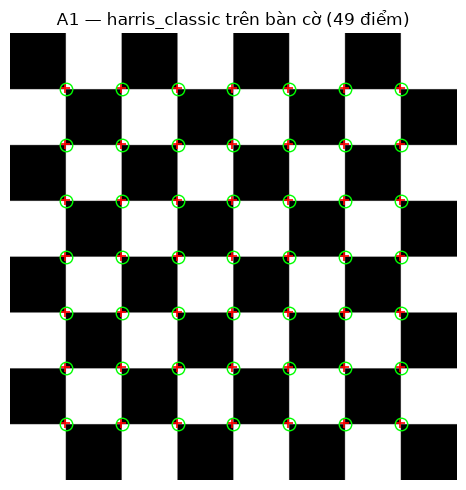

In [7]:
print("=" * 60)
print("A1. Bàn cờ tổng hợp")
canh, n_o = 32, 8
ban_co = tao_ban_co(n_o, canh)
luu_anh(ban_co, "a0_ban_co.png")

pts = harris_classic(ban_co)
# Giao điểm trong nằm giữa pixel canh*k - 1 và canh*k, tức là tại canh*k - 0.5.
g = np.array([canh * k - 0.5 for k in range(1, n_o)])
truth = np.array([(r, c) for r in g for c in g])

d = np.sqrt(((pts[:, None, :2] - truth[None, :, :]) ** 2).sum(axis=2))
gan_nhat_cua_truth = d.min(axis=0)          # mỗi giao điểm -> điểm phát hiện gần nhất
gan_nhat_cua_pts = d.min(axis=1)            # mỗi điểm phát hiện -> giao điểm gần nhất
n_khop = int((gan_nhat_cua_truth <= 1.0).sum())
n_thua = int((gan_nhat_cua_pts > 1.0).sum())
print(f"Số giao điểm trong (đáp án): {len(truth)}")
print(f"Số điểm harris_classic trả về: {len(pts)}")
print(f"Số giao điểm tìm được với sai số <= 1 px: {n_khop}/{len(truth)}")
print(f"Số điểm thừa (cách mọi giao điểm > 1 px): {n_thua}")
print(f"Sai số lớn nhất: {gan_nhat_cua_truth.max():.3f} px")
print("ĐẠT" if (n_khop == len(truth) and n_thua == 0) else "CHƯA ĐẠT")

fig, ax = plt.subplots(figsize=(5, 5))
show_points(ax, ban_co, pts, f"A1 — harris_classic trên bàn cờ ({len(pts)} điểm)")
ax.plot(truth[:, 1], truth[:, 0], "o", mfc="none", mec="lime", ms=9, mew=1)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "a1_ban_co.png"), dpi=120)
plt.show()

#### KIỂM CHỨNG A2 — Bất biến phép quay (30°)

**Prompt AI** — Người 1 · công cụ: Antigravity IDE · ngày 9/11/2026
> Tạo ảnh cảnh tổng hợp, xoay 30 độ bằng make_rotation, chạy harris_classic
> trên cả hai ảnh và tính repeatability với eps=3.0 px. Vẽ ảnh gốc và ảnh
> quay kèm điểm chiếu sang ket_qua/a2_quay_30.png.

A2. Bất biến phép quay (30°)
Số điểm ảnh gốc: 15 | ảnh quay 30°: 15
Repeatability (gốc -> quay, eps = 3 px): 1.000


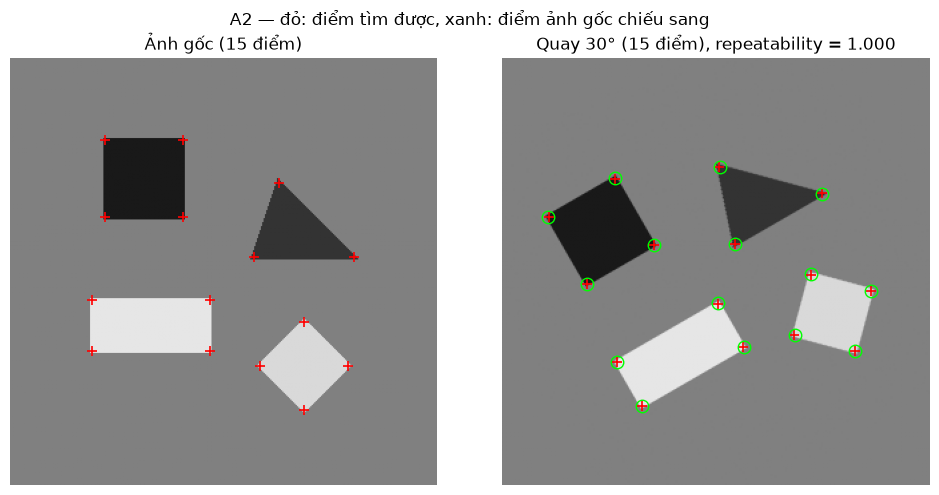

In [8]:
print("=" * 60)
print("A2. Bất biến phép quay (30°)")
canh_th = tao_canh_tong_hop()
luu_anh(canh_th, "a0_canh_tong_hop.png")
quay, tf = make_rotation(canh_th, 30)
luu_anh(quay, "a0_canh_tong_hop_quay30.png")

pa = harris_classic(canh_th)
pb = harris_classic(quay)
rep = repeatability(pa, pb, tf, quay.shape, eps=3.0)
print(f"Số điểm ảnh gốc: {len(pa)} | ảnh quay 30°: {len(pb)}")
print(f"Repeatability (gốc -> quay, eps = 3 px): {rep:.3f}")

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
show_points(axs[0], canh_th, pa, f"Ảnh gốc ({len(pa)} điểm)")
r_proj, c_proj = tf(pa[:, 0], pa[:, 1])
show_points(axs[1], quay, pb, f"Quay 30° ({len(pb)} điểm), repeatability = {rep:.3f}")
axs[1].plot(c_proj, r_proj, "o", mfc="none", mec="lime", ms=9, mew=1)
fig.suptitle("A2 — đỏ: điểm tìm được, xanh: điểm ảnh gốc chiếu sang")
fig.tight_layout()
fig.savefig(os.path.join(OUT, "a2_quay_30.png"), dpi=120)
plt.show()

#### KIỂM CHỨNG A4 — Đối chiếu với cv2.cornerHarris

**Prompt AI** — Người 1 · công cụ: Antigravity IDE · ngày 9/11/2026
> Đối chiếu kết quả harris_classic tự cài đặt với cv2.cornerHarris
> (blockSize=5, ksize=3, k=0.04) trên 3 ảnh (bàn cờ, cảnh tổng hợp,
> cảnh quay 30°). Tính tỉ lệ điểm khớp trong bán kính 2px, 3px và lưu
> hình so sánh vào ket_qua/a4_doi_chieu_opencv.png.

A4. Đối chiếu với cv2.cornerHarris
Tham số OpenCV: blockSize=5, ksize=3, k=0.04
Tham số của mình: sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.01
bàn cờ         : của mình  49 điểm, OpenCV  49 điểm | trong 2 px: 1.000 | trong 3 px: 1.000
cảnh tổng hợp  : của mình  15 điểm, OpenCV  15 điểm | trong 2 px: 1.000 | trong 3 px: 1.000
cảnh quay 30°  : của mình  15 điểm, OpenCV  15 điểm | trong 2 px: 1.000 | trong 3 px: 1.000


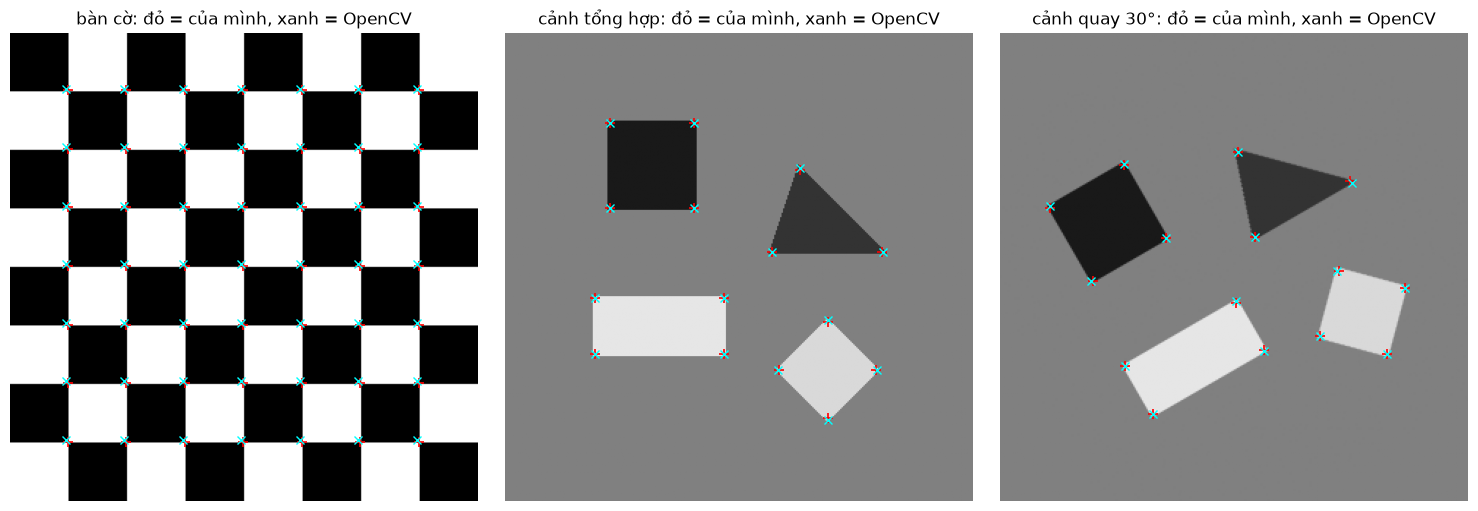

Hình đã lưu trong ket_qua/


In [9]:
# đối chiếu thư viện
print("=" * 60)
print("A4. Đối chiếu với cv2.cornerHarris")
BLOCK, KSIZE, K = 5, 3, 0.04   # cửa sổ 5x5 ~ sigma_i = 2; Sobel 3x3; cùng k
print(f"Tham số OpenCV: blockSize={BLOCK}, ksize={KSIZE}, k={K}")
print("Tham số của mình: sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.01")


def diem_opencv(img, thresh_rel=0.01, margin=6):
    R = cv2.cornerHarris(img.astype(np.float32), BLOCK, KSIZE, K).astype(np.float64)
    mask = nms_2d(R) & (R > thresh_rel * R.max()) & (R > 0)
    mask[:margin, :] = mask[-margin:, :] = False
    mask[:, :margin] = mask[:, -margin:] = False
    rr, cc = np.nonzero(mask)
    return np.column_stack([rr, cc]).astype(np.float64)


def ti_le_trong_ban_kinh(p_minh, p_cv, rad=3.0):
    if len(p_minh) == 0 or len(p_cv) == 0:
        return float("nan")
    d = np.sqrt(((p_minh[:, None, :2] - p_cv[None, :, :2]) ** 2).sum(axis=2))
    return float((d.min(axis=1) <= rad).mean())


ket_qua_a4 = []
for ten, img in [("bàn cờ", ban_co), ("cảnh tổng hợp", canh_th), ("cảnh quay 30°", quay)]:
    p_minh = harris_classic(img)
    p_cv = diem_opencv(img)
    t3 = ti_le_trong_ban_kinh(p_minh, p_cv, 3.0)
    t2 = ti_le_trong_ban_kinh(p_minh, p_cv, 2.0)
    ket_qua_a4.append((ten, img, p_minh, p_cv))
    print(f"{ten:15s}: của mình {len(p_minh):3d} điểm, OpenCV {len(p_cv):3d} điểm | "
          f"trong 2 px: {t2:.3f} | trong 3 px: {t3:.3f}")

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, (ten, img, p_minh, p_cv) in zip(axs, ket_qua_a4):
    show_points(ax, img, p_minh, f"{ten}: đỏ = của mình, xanh = OpenCV")
    ax.plot(p_cv[:, 1], p_cv[:, 0], "x", color="cyan", ms=6, mew=1)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "a4_doi_chieu_opencv.png"), dpi=110)
plt.show()

print("=" * 60)
print("Hình đã lưu trong ket_qua/")

## A.5 Kiểm chứng A3 và thí nghiệm A1 vs Harris (Người 2)

**Prompt AI** — Người 2 · công cụ: Antigravity IDE · ngày 11/11/2026
> Viết phần nhập khẩu, hằng đường dẫn và hàm tải ảnh cho script
> kiểm chứng A3 & thí nghiệm A1 vs Harris, dùng oxford/bark/img1.png.

In [10]:
import os

import matplotlib.pyplot as plt
import numpy as np


_DIR = os.getcwd()
_KQ  = os.path.join(_DIR, "ket_qua")
os.makedirs(_KQ, exist_ok=True)

# Ảnh kết cấu thực (Oxford Bark) — cấu trúc tự nhiên, không lý tưởng:
# Harris cổ điển thất bại rõ khi đổi tỉ lệ, Harris–Laplace vượt trội.
IMG_PATH = os.path.join(_DIR, "anh", "oxford", "bark", "img1.png")

_SIGMAS_16 = scale_pyramid(sigma0=1.2, xi=1.2, n_levels=16)   # sigma_max ≈ 18.5

#### KIỂM CHỨNG A3 — Repeatability Harris vs Harris–Laplace (1→3×)

**Prompt AI** — Người 2 · công cụ: Antigravity IDE · ngày 11/11/2026
> Tải oxford/bark/img1.png, phóng to 3×, phát hiện điểm bằng
> harris_classic và harris_laplace (n_levels=16), tính và in
> repeatability 1→3× cho cả hai phương pháp.

In [11]:
def run_kiem_chung_a3():
    img      = load_gray(IMG_PATH)
    img_3x, tf = make_scale(img, 3.0)

    # Đánh giá khách quan: cả hai phương pháp dùng cùng cấu hình mặc định trên cả hai ảnh
    pts_h1 = harris_classic(img)
    pts_h3 = harris_classic(img_3x)
    pts_l1 = harris_laplace(img,    _SIGMAS_16)
    pts_l3 = harris_laplace(img_3x, _SIGMAS_16)

    rep_h = repeatability(pts_h1, pts_h3, tf, img_3x.shape)
    rep_l = repeatability(pts_l1, pts_l3, tf, img_3x.shape)

    print("=" * 56)
    print("KIỂM CHỨNG A3 — Bất biến Tỉ lệ  (ảnh: oxford/bark)")
    print(f"  sigma_min={_SIGMAS_16[0]:.3f}  sigma_max={_SIGMAS_16[-1]:.3f}")
    print("-" * 56)
    print(f"  Harris cổ điển : repeatability 1→3× = {rep_h:.3f}"
          f"  ({len(pts_h1)} / {len(pts_h3)} điểm)")
    print(f"  Harris–Laplace : repeatability 1→3× = {rep_l:.3f}"
          f"  ({len(pts_l1)} / {len(pts_l3)} điểm)")
    print("=" * 56)

    return img, img_3x, tf




img, img_3x, tf = run_kiem_chung_a3()

KIỂM CHỨNG A3 — Bất biến Tỉ lệ  (ảnh: oxford/bark)
  sigma_min=1.200  sigma_max=18.488
--------------------------------------------------------
  Harris cổ điển : repeatability 1→3× = 0.265  (709 / 1929 điểm)
  Harris–Laplace : repeatability 1→3× = 0.848  (900 / 1625 điểm)


#### 5.1.1 — Trực quan hóa điểm qua các hệ số tỉ lệ

**Prompt AI** — Người 2 · công cụ: Antigravity IDE · ngày 11/11/2026
> Vẽ lưới 2×4: hàng trên Harris cổ điển (dấu + đỏ), hàng dưới
> Harris–Laplace (vòng tròn xanh lá r=2σ), qua 1×/1.5×/2×/3×.
> Lưu vào ket_qua/a1_scale_evidence.png.

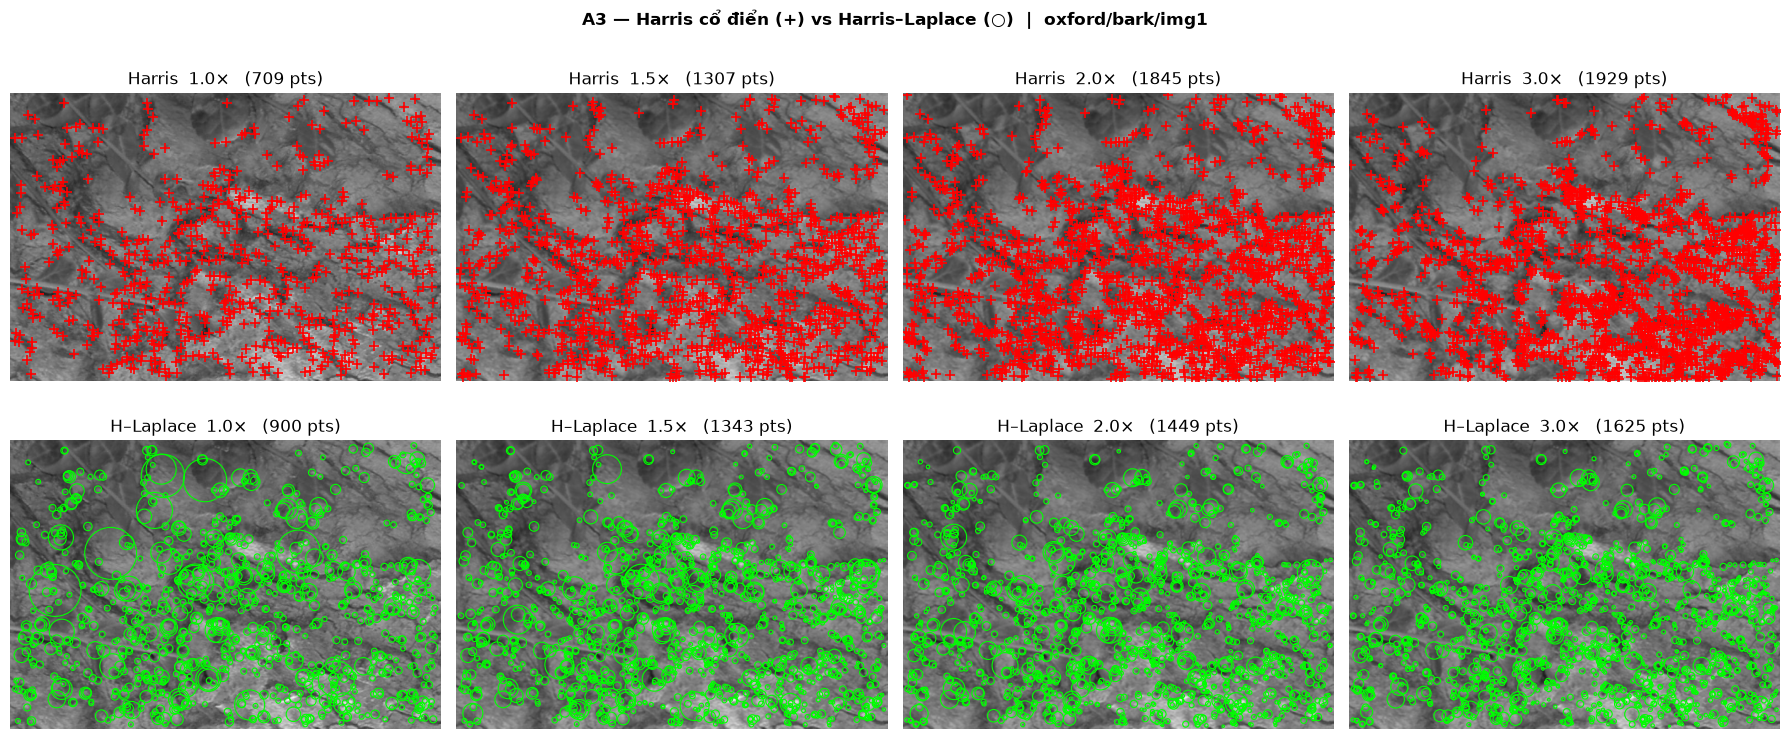

[OK] c:\University\ComputerVision2\ket_qua\a1_scale_evidence.png


In [12]:
def run_evidence(img):
    factors = [1.0, 1.5, 2.0, 3.0]
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    fig.suptitle(
        "A3 — Harris cổ điển (+) vs Harris–Laplace (○)  |  oxford/bark/img1",
        fontsize=12, fontweight="bold"
    )

    for col, f in enumerate(factors):
        img_f = img if f == 1.0 else make_scale(img, f)[0]

        # Harris cổ điển dùng cùng tham số mặc định trên mọi tỉ lệ
        pts_h = harris_classic(img_f)
        pts_l = harris_laplace(img_f, _SIGMAS_16)

        show_points(axes[0, col], img_f, pts_h,
                    title=f"Harris  {f:.1f}×   ({len(pts_h)} pts)",
                    color="red", circles=False)
        show_points(axes[1, col], img_f, pts_l,
                    title=f"H–Laplace  {f:.1f}×   ({len(pts_l)} pts)",
                    color="lime", circles=True)

    plt.tight_layout()
    out = os.path.join(_KQ, "a1_scale_evidence.png")
    plt.savefig(out, dpi=120, bbox_inches="tight")
    plt.show()
    print(f"[OK] {out}")




run_evidence(img)

#### 5.1.2 — Quét tham số ξ và log_thresh

**Prompt AI** — Người 2 · công cụ: Antigravity IDE · ngày 11/11/2026
> Quét xi trong [1.1, 1.5] (9 điểm) dùng _harris_laplace_debug để
> tính rejection_rate = 1 - n_step2/n_step1.
> Quét log_thresh trong [0, 0.05] (9 điểm) tính repeatability 1→3×.
> Vẽ 2 biểu đồ có nhãn trục, đơn vị, grid. Lưu ket_qua/a1_param_sweep.png.

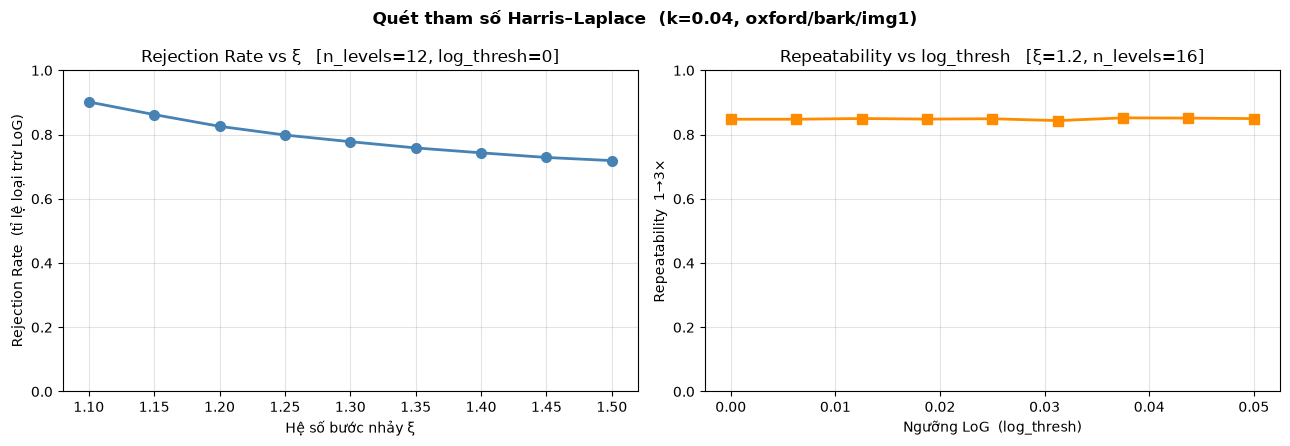

[OK] c:\University\ComputerVision2\ket_qua\a1_param_sweep.png


In [13]:
def run_param_sweep(img):
    img_3x, tf = make_scale(img, 3.0)

    xi_vals  = np.linspace(1.1, 1.5, 9)
    lt_vals  = np.linspace(0.0, 0.05, 9)

    # Quét xi: đo rejection rate
    rej_rates = []
    for xi in xi_vals:
        sigs = scale_pyramid(sigma0=1.2, xi=xi, n_levels=12)
        _, n1, n2 = _harris_laplace_debug(img, sigs)
        rej_rates.append(1.0 - n2 / n1 if n1 > 0 else 1.0)

    # Quét log_thresh: tính repeatability 1→3×
    rep_vals = []
    for lt in lt_vals:
        p1 = harris_laplace(img,    _SIGMAS_16, log_thresh=lt)
        p3 = harris_laplace(img_3x, _SIGMAS_16, log_thresh=lt)
        r  = repeatability(p1, p3, tf, img_3x.shape)
        rep_vals.append(float(r) if np.isfinite(r) else 0.0)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
    fig.suptitle(
        "Quét tham số Harris–Laplace  (k=0.04, oxford/bark/img1)",
        fontsize=12, fontweight="bold"
    )

    ax1.plot(xi_vals, rej_rates, "o-", color="steelblue", lw=2, ms=7)
    ax1.set_xlabel("Hệ số bước nhảy ξ")
    ax1.set_ylabel("Rejection Rate  (tỉ lệ loại trừ LoG)")
    ax1.set_title("Rejection Rate vs ξ   [n_levels=12, log_thresh=0]")
    ax1.set_ylim(0, 1)
    ax1.grid(True, alpha=0.35)

    ax2.plot(lt_vals, rep_vals, "s-", color="darkorange", lw=2, ms=7)
    ax2.set_xlabel("Ngưỡng LoG  (log_thresh)")
    ax2.set_ylabel("Repeatability  1→3×")
    ax2.set_title("Repeatability vs log_thresh   [ξ=1.2, n_levels=16]")
    ax2.set_ylim(0, 1)
    ax2.grid(True, alpha=0.35)

    plt.tight_layout()
    out = os.path.join(_KQ, "a1_param_sweep.png")
    plt.savefig(out, dpi=120, bbox_inches="tight")
    plt.show()
    print(f"[OK] {out}")




run_param_sweep(img)

#### 5.1.3 — Cơ chế bất biến tỉ lệ

**Prompt AI** — Người 2 · công cụ: Antigravity IDE · ngày 11/11/2026
> Soạn đoạn văn súc tích trả lời 3 câu hỏi cơ chế bất biến tỉ lệ
> của Harris–Laplace: đại lượng nào, bước nào, vì sao bất biến.

In [14]:
_MECHANISM = """\
CƠ CHẾ BẤT BIẾN TỈ LỆ — Harris–Laplace (A1)
─────────────────────────────────────────────
(1) Đại lượng: σ²·|ΔL| — Laplacian-of-Gaussian chuẩn hóa Lindeberg.
    Khi ảnh phóng k lần, biên độ LoG thô giảm 1/k², nhưng thừa số σ²
    bù lại đúng k² (vì σ tối ưu tỉ lệ thuận k) → giá trị chuẩn hóa
    tại điểm đặc trưng là hằng số theo tỉ lệ.

(2) Bước thực hiện: Bước 2 của harris_laplace — chọn tỉ lệ bằng cực
    đại địa phương của log_stack theo trục tháp. Khi ảnh thay đổi tỉ
    lệ, cực đại dịch sang tầng σ_new ≈ k·σ_old nhưng vẫn là cực đại
    → điểm đặc trưng được tìm lại ở tỉ lệ đúng.

(3) Lý thuyết (Lindeberg 1998): đáp ứng LoG chuẩn hóa đạt cực đại
    theo σ chính xác khi σ khớp với "tỉ lệ đặc trưng" của cấu trúc.
    Phép phóng/thu chỉ dịch vị trí cực đại trong tháp σ, không phá
    hủy tính cực đại → thuật toán tự chọn đúng σ ở cả hai ảnh.
─────────────────────────────────────────────"""


def print_mechanism():
    print(_MECHANISM)




print_mechanism()

CƠ CHẾ BẤT BIẾN TỈ LỆ — Harris–Laplace (A1)
─────────────────────────────────────────────
(1) Đại lượng: σ²·|ΔL| — Laplacian-of-Gaussian chuẩn hóa Lindeberg.
    Khi ảnh phóng k lần, biên độ LoG thô giảm 1/k², nhưng thừa số σ²
    bù lại đúng k² (vì σ tối ưu tỉ lệ thuận k) → giá trị chuẩn hóa
    tại điểm đặc trưng là hằng số theo tỉ lệ.

(2) Bước thực hiện: Bước 2 của harris_laplace — chọn tỉ lệ bằng cực
    đại địa phương của log_stack theo trục tháp. Khi ảnh thay đổi tỉ
    lệ, cực đại dịch sang tầng σ_new ≈ k·σ_old nhưng vẫn là cực đại
    → điểm đặc trưng được tìm lại ở tỉ lệ đúng.

(3) Lý thuyết (Lindeberg 1998): đáp ứng LoG chuẩn hóa đạt cực đại
    theo σ chính xác khi σ khớp với "tỉ lệ đặc trưng" của cấu trúc.
    Phép phóng/thu chỉ dịch vị trí cực đại trong tháp σ, không phá
    hủy tính cực đại → thuật toán tự chọn đúng σ ở cả hai ảnh.
─────────────────────────────────────────────


## A.6 Kiểm chứng A5 và thí nghiệm A2 vs Harris (Người 3)

**Prompt AI** — Người 3 · công cụ: Antigravity IDE · ngày 10/11/2026
> Viết phần import, hằng đường dẫn, hàm tính khoảng cách láng giềng gần nhất
> kc_lang_gieng, hàm giảm tương phản nửa trái ảnh và khởi tạo tập ứng viên
> Harris (thresh_rel=0.001) trên ảnh oxford/boat/img1.

In [15]:
import os

import cv2
import matplotlib.pyplot as plt
import numpy as np


HERE = os.getcwd()
OUT = os.path.join(HERE, "ket_qua")
ANH = os.path.join(HERE, "anh")
os.makedirs(OUT, exist_ok=True)
os.makedirs(ANH, exist_ok=True)

THRESH_UNG_VIEN = 0.001   # ngưỡng thấp để có nhiều ứng viên; top_n và anms chọn trên CÙNG tập này


def kc_lang_gieng(pts):
    """Khoảng cách trung bình từ mỗi điểm tới điểm gần nhất (px). Lớn hơn = trải đều hơn."""
    if len(pts) < 2:
        return float("nan")
    d = np.sqrt(((pts[:, None, :2] - pts[None, :, :2]) ** 2).sum(axis=2))
    np.fill_diagonal(d, np.inf)
    return float(d.min(axis=1).mean())


def giam_tuong_phan_nua_trai(img, he_so):
    """Giữ nguyên nửa phải, nén tương phản nửa trái quanh giá trị trung bình."""
    out = img.copy()
    W = img.shape[1]
    m = img.mean()
    out[:, :W // 2] = m + (img[:, :W // 2] - m) * he_so
    return out


img, _ = load_oxford("boat", 1)
H, W = img.shape
ung_vien = harris_classic(img, thresh_rel=THRESH_UNG_VIEN)

#### KIỂM CHỨNG A5 — Phân bố điểm: top_n vs ANMS

**Prompt AI** — Người 3 · công cụ: Antigravity IDE · ngày 10/11/2026
> So sánh độ phủ lưới (grid_occupancy) và khoảng cách láng giềng gần nhất
> giữa top_n và anms (c_robust=0.9) với N=100 và N=300 trên cùng tập ứng viên.
> Vẽ lưới 2×2 và lưu vào ket_qua/a5_topn_vs_anms.png.

A5. Phân bố điểm: top_n vs anms (ảnh oxford/boat/img1, c_robust = 0.9)
Số ứng viên Harris (thresh_rel = 0.001): 925
    N |  phủ lưới top_n |  phủ lưới anms |  kc láng giềng top_n |   anms
  100 |           0.453 |          0.844 |              13.8 px | 28.6 px
  300 |           0.594 |          0.938 |               9.4 px | 16.3 px


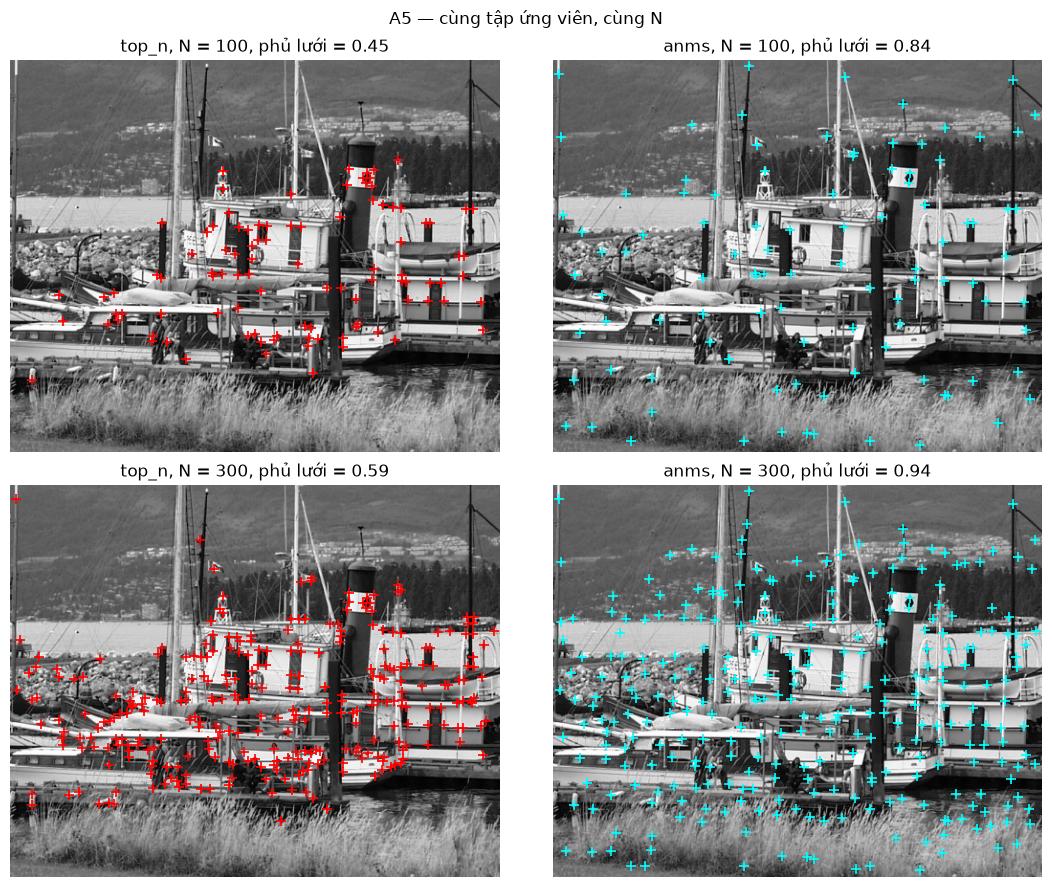

In [16]:
print("=" * 64)
print("A5. Phân bố điểm: top_n vs anms (ảnh oxford/boat/img1, c_robust = 0.9)")
print(f"Số ứng viên Harris (thresh_rel = {THRESH_UNG_VIEN}): {len(ung_vien)}")
print(f"{'N':>5} | {'phủ lưới top_n':>15} | {'phủ lưới anms':>14} | {'kc láng giềng top_n':>20} | {'anms':>6}")
fig, axs = plt.subplots(2, 2, figsize=(11, 9))
for i, N in enumerate([100, 300]):
    pt, pa = top_n(ung_vien, N), anms(ung_vien, N)
    ct, ca = grid_occupancy(pt, img.shape), grid_occupancy(pa, img.shape)
    print(f"{N:>5} | {ct:>15.3f} | {ca:>14.3f} | {kc_lang_gieng(pt):>17.1f} px | {kc_lang_gieng(pa):>4.1f} px")
    show_points(axs[i, 0], img, pt, f"top_n, N = {N}, phủ lưới = {ct:.2f}")
    show_points(axs[i, 1], img, pa, f"anms, N = {N}, phủ lưới = {ca:.2f}", color="cyan")
fig.suptitle("A5 — cùng tập ứng viên, cùng N")
fig.tight_layout()
fig.savefig(os.path.join(OUT, "a5_topn_vs_anms.png"), dpi=110)
plt.show()

#### 6.1 — Bằng chứng khác biệt khi giảm tương phản cục bộ

**Prompt AI** — Người 3 · công cụ: Antigravity IDE · ngày 10/11/2026
> Nén tương phản nửa trái ảnh xuống 30%, chạy harris_classic lấy ứng viên
> rồi chọn N=100 điểm bằng top_n và anms. Tính tỉ lệ điểm rơi vào nửa trái,
> vẽ hình đối chiếu có vạch chia đôi ảnh lưu vào ket_qua/a2_bang_chung_tuong_phan.png.

6.1 Bằng chứng: nửa trái ảnh bị giảm tương phản còn 30%
Ứng viên: 578, trong đó 84 ở nửa trái (ứng viên vẫn còn, chỉ là R nhỏ)
N = 100: tỉ lệ điểm ở nửa trái  top_n = 0.00 | anms = 0.30
        phủ lưới                top_n = 0.297 | anms = 0.734


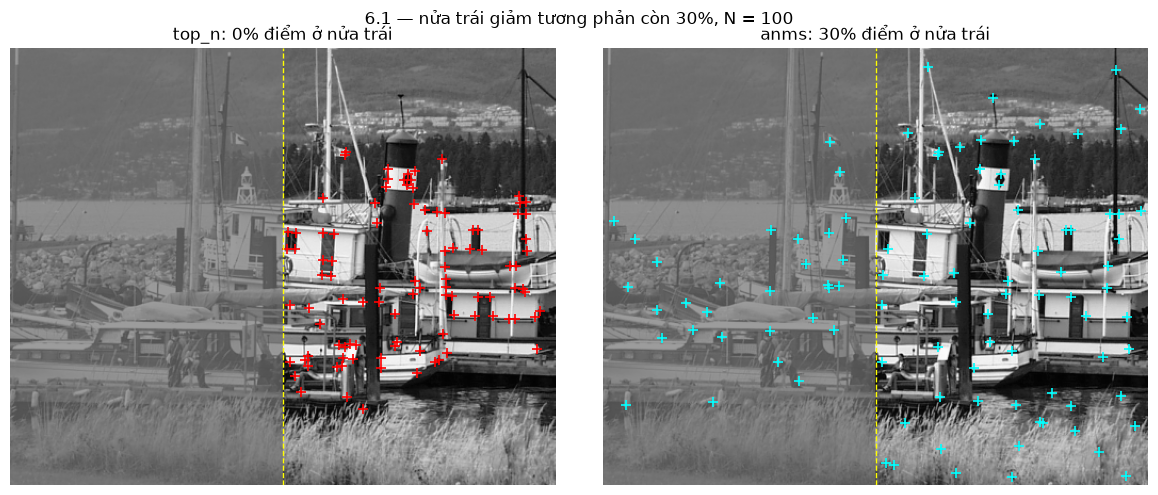

In [17]:
print("=" * 64)
print("6.1 Bằng chứng: nửa trái ảnh bị giảm tương phản còn 30%")
HE_SO = 0.3
anh_tp = giam_tuong_phan_nua_trai(img, HE_SO)
cv2.imwrite(os.path.join(ANH, "a2_boat_nua_trai_tp30.png"), np.round(np.clip(anh_tp, 0, 1) * 255).astype(np.uint8))
uv_tp = harris_classic(anh_tp, thresh_rel=THRESH_UNG_VIEN)
N = 100
pt, pa = top_n(uv_tp, N), anms(uv_tp, N)
trai_t = (pt[:, 1] < W / 2).mean()
trai_a = (pa[:, 1] < W / 2).mean()
uv_trai = (uv_tp[:, 1] < W / 2).sum()
print(f"Ứng viên: {len(uv_tp)}, trong đó {uv_trai} ở nửa trái (ứng viên vẫn còn, chỉ là R nhỏ)")
print(f"N = {N}: tỉ lệ điểm ở nửa trái  top_n = {trai_t:.2f} | anms = {trai_a:.2f}")
print(f"        phủ lưới                top_n = {grid_occupancy(pt, img.shape):.3f} | anms = {grid_occupancy(pa, img.shape):.3f}")
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
show_points(axs[0], anh_tp, pt, f"top_n: {trai_t:.0%} điểm ở nửa trái")
show_points(axs[1], anh_tp, pa, f"anms: {trai_a:.0%} điểm ở nửa trái", color="cyan")
for ax in axs:
    ax.axvline(W / 2, color="yellow", lw=1, ls="--")
fig.suptitle(f"6.1 — nửa trái giảm tương phản còn {HE_SO:.0%}, N = {N}")
fig.tight_layout()
fig.savefig(os.path.join(OUT, "a2_bang_chung_tuong_phan.png"), dpi=110)
plt.show()

#### 6.2 — Quét tham số (tương phản nửa trái, số điểm N, c_robust)

**Prompt AI** — Người 3 · công cụ: Antigravity IDE · ngày 10/11/2026
> Thực hiện 3 phép quét tham số: (6.2a) quét hệ số tương phản nửa trái từ
> 1.0 xuống 0.1; (6.2b) quét số điểm N từ 25 đến tổng ứng viên; (6.2c) quét
> c_robust từ 0.5 đến 1.0 đo kc láng giềng và số điểm r=inf. Vẽ 3 biểu đồ
> ngang hàng và lưu vào ket_qua/a2_quet_tham_so.png.

6.2a Quét mức tương phản nửa trái (N = 100): top_n bỏ hẳn nửa trái từ đâu?
  hệ số 1.0 (R nửa trái x 1.0000): nửa trái top_n = 0.37 | anms = 0.47 | ứng viên còn ở nửa trái: 458
  hệ số 0.9 (R nửa trái x 0.6561): nửa trái top_n = 0.26 | anms = 0.45 | ứng viên còn ở nửa trái: 450
  hệ số 0.8 (R nửa trái x 0.4096): nửa trái top_n = 0.14 | anms = 0.44 | ứng viên còn ở nửa trái: 414
  hệ số 0.7 (R nửa trái x 0.2401): nửa trái top_n = 0.05 | anms = 0.41 | ứng viên còn ở nửa trái: 371
  hệ số 0.6 (R nửa trái x 0.1296): nửa trái top_n = 0.01 | anms = 0.40 | ứng viên còn ở nửa trái: 337
  hệ số 0.5 (R nửa trái x 0.0625): nửa trái top_n = 0.00 | anms = 0.38 | ứng viên còn ở nửa trái: 284
  hệ số 0.4 (R nửa trái x 0.0256): nửa trái top_n = 0.00 | anms = 0.36 | ứng viên còn ở nửa trái: 177
  hệ số 0.3 (R nửa trái x 0.0081): nửa trái top_n = 0.00 | anms = 0.30 | ứng viên còn ở nửa trái: 84
  hệ số 0.2 (R nửa trái x 0.0016): nửa trái top_n = 0.00 | anms = 0.04 | ứng viên còn ở nửa trái: 5
  hệ số 0.

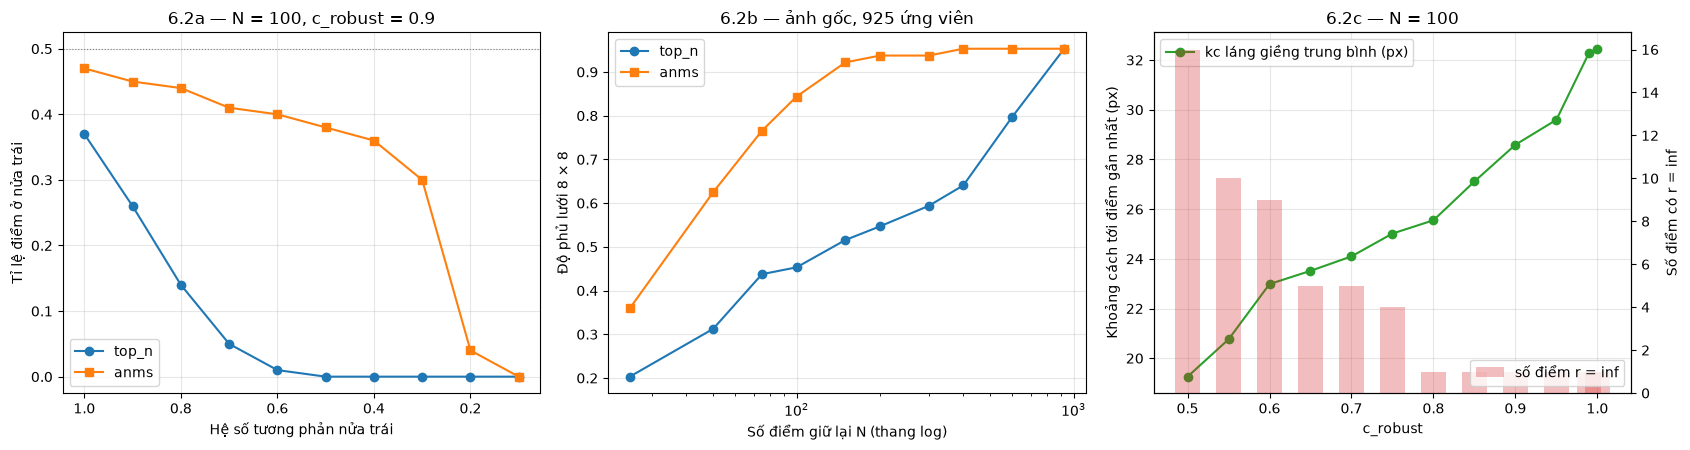

In [18]:
print("=" * 64)
print("6.2a Quét mức tương phản nửa trái (N = 100): top_n bỏ hẳn nửa trái từ đâu?")
he_so_ds = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1]
trai_top, trai_anms, uv_trai_ds = [], [], []
for hs in he_so_ds:
    uv = harris_classic(giam_tuong_phan_nua_trai(img, hs), thresh_rel=THRESH_UNG_VIEN)
    trai_top.append((top_n(uv, 100)[:, 1] < W / 2).mean())
    trai_anms.append((anms(uv, 100)[:, 1] < W / 2).mean())
    uv_trai_ds.append(int((uv[:, 1] < W / 2).sum()))
    print(f"  hệ số {hs:.1f} (R nửa trái x {hs ** 4:.4f}): nửa trái top_n = {trai_top[-1]:.2f} | anms = {trai_anms[-1]:.2f}"
          f" | ứng viên còn ở nửa trái: {uv_trai_ds[-1]}")

print("6.2b Quét N (ảnh gốc): độ phủ lưới theo số điểm giữ lại")
N_ds = [25, 50, 75, 100, 150, 200, 300, 400, 600, len(ung_vien)]
phu_top = [grid_occupancy(top_n(ung_vien, n), img.shape) for n in N_ds]
phu_anms = [grid_occupancy(anms(ung_vien, n), img.shape) for n in N_ds]
for n, a, b in zip(N_ds, phu_top, phu_anms):
    print(f"  N = {n:4d}: top_n = {a:.3f} | anms = {b:.3f}")

print("6.2c Quét c_robust (ảnh gốc, N = 100)")
c_ds = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99, 1.0]
phu_c, kc_c, so_inf = [], [], []
for c in c_ds:
    pa = anms(ung_vien, 100, c_robust=c)
    phu_c.append(grid_occupancy(pa, img.shape))
    kc_c.append(kc_lang_gieng(pa))
    so_inf.append(int(np.isinf(_anms_radii(ung_vien, c)).sum()))
    print(f"  c = {c:.2f}: phủ lưới = {phu_c[-1]:.3f} | kc láng giềng = {kc_c[-1]:5.1f} px | số điểm r = inf: {so_inf[-1]}")

fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axs[0]
ax.plot(he_so_ds, trai_top, "o-", label="top_n")
ax.plot(he_so_ds, trai_anms, "s-", label="anms")
ax.axhline(0.5, color="gray", lw=0.8, ls=":")
ax.invert_xaxis()
ax.set_xlabel("Hệ số tương phản nửa trái")
ax.set_ylabel("Tỉ lệ điểm ở nửa trái")
ax.set_title("6.2a — N = 100, c_robust = 0.9")
ax.legend()
ax.grid(alpha=0.3)

ax = axs[1]
ax.plot(N_ds, phu_top, "o-", label="top_n")
ax.plot(N_ds, phu_anms, "s-", label="anms")
ax.set_xscale("log")
ax.set_xlabel("Số điểm giữ lại N (thang log)")
ax.set_ylabel("Độ phủ lưới 8 × 8")
ax.set_title(f"6.2b — ảnh gốc, {len(ung_vien)} ứng viên")
ax.legend()
ax.grid(alpha=0.3)

ax = axs[2]
ax.plot(c_ds, kc_c, "o-", color="C2", label="kc láng giềng trung bình (px)")
ax.set_xlabel("c_robust")
ax.set_ylabel("Khoảng cách tới điểm gần nhất (px)")
ax2 = ax.twinx()
ax2.bar(c_ds, so_inf, width=0.03, alpha=0.3, color="C3", label="số điểm r = inf")
ax2.set_ylabel("Số điểm có r = inf")
ax.set_title("6.2c — N = 100")
ax.legend(loc="upper left")
ax2.legend(loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "a2_quet_tham_so.png"), dpi=110)
plt.show()

#### 6.3 — Cơ chế và giải thích hiện tượng (ANMS vs top-N)

**Prompt AI** — Người 3 · công cụ: Antigravity IDE · ngày 10/11/2026
> Viết đoạn giải thích cơ chế của ANMS so với top_n theo 3 ý: đại lượng
> tính khác nhau (f_i vs bán kính ức chế r_i), bước áp dụng, và giải thích
> kết quả thực nghiệm ở mục 6.1, 6.2a, 6.2b, 6.2c.

In [19]:
print("=" * 64)
print("""6.3 Giải thích
(1) Đại lượng tính khác: top_n xếp hạng điểm theo response f_i. ANMS xếp hạng theo
    bán kính ức chế r_i = khoảng cách tới điểm gần nhất mạnh hơn đáng kể (f_i < c·f_j).
    r_i là đại lượng hình học: nó chỉ dùng f để so sánh hơn-kém, không dùng độ lớn của f.
(2) Bước: sau harris_classic, ở bước chọn N điểm cuối cùng. Phần phát hiện ứng viên
    giữ nguyên, hai cách dùng chung một tập ứng viên.
(3) Vì sao ra đúng hiện tượng:
    - M chứa tích đạo hàm nên tỉ lệ với bình phương tương phản; R = det − k·tr² tỉ lệ
      với lũy thừa 4. Nửa trái giảm còn 30% thì R ở đó nhân 0.3^4 ≈ 0.008, nên mọi
      điểm nửa trái tụt xuống cuối bảng xếp hạng và top_n bỏ hẳn nửa trái (6.1, 6.2a).
    - Với ANMS, điểm mạnh nhất của nửa trái chỉ bị các điểm nửa phải ức chế, mà
      chúng ở xa, nên r của nó lớn và nó vẫn được chọn sớm. Vì vậy anms giữ được
      khoảng 1/3–1/2 số điểm ở nửa trái tới hệ số 0.3.
    - Từ hệ số 0.2 thì anms cũng mất nửa trái. Lý do không nằm ở ANMS mà ở bước trước:
      R nửa trái chỉ còn khoảng 0.0016 lần, rơi dưới ngưỡng thresh_rel·max(R) của
      harris_classic, nên ứng viên nửa trái gần như không còn để ANMS chọn. ANMS chỉ
      sắp xếp lại các ứng viên, không tạo thêm ứng viên.
    - c_robust nhỏ thì điều kiện f_i < c·f_j khó thỏa hơn, nhiều điểm không có ai ức
      chế (r = inf). Các điểm r = inf được chọn trước bất kể vị trí, nên ANMS lùi dần
      về hành vi của top_n: khoảng cách láng giềng giảm đều từ 32.5 xuống 19.3 px (6.2c).
      Độ phủ lưới cũng giảm theo xu hướng nhưng dao động, vì lưới 8 × 8 khá thô.
    - Khi N tiến tới tổng số ứng viên, hai cách chọn gần như cùng một tập điểm nên
      hai đường độ phủ gặp nhau (6.2b).""")
print("Hình đã lưu trong ket_qua/")

6.3 Giải thích
(1) Đại lượng tính khác: top_n xếp hạng điểm theo response f_i. ANMS xếp hạng theo
    bán kính ức chế r_i = khoảng cách tới điểm gần nhất mạnh hơn đáng kể (f_i < c·f_j).
    r_i là đại lượng hình học: nó chỉ dùng f để so sánh hơn-kém, không dùng độ lớn của f.
(2) Bước: sau harris_classic, ở bước chọn N điểm cuối cùng. Phần phát hiện ứng viên
    giữ nguyên, hai cách dùng chung một tập ứng viên.
(3) Vì sao ra đúng hiện tượng:
    - M chứa tích đạo hàm nên tỉ lệ với bình phương tương phản; R = det − k·tr² tỉ lệ
      với lũy thừa 4. Nửa trái giảm còn 30% thì R ở đó nhân 0.3^4 ≈ 0.008, nên mọi
      điểm nửa trái tụt xuống cuối bảng xếp hạng và top_n bỏ hẳn nửa trái (6.1, 6.2a).
    - Với ANMS, điểm mạnh nhất của nửa trái chỉ bị các điểm nửa phải ức chế, mà
      chúng ở xa, nên r của nó lớn và nó vẫn được chọn sớm. Vì vậy anms giữ được
      khoảng 1/3–1/2 số điểm ở nửa trái tới hệ số 0.3.
    - Từ hệ số 0.2 thì anms cũng mất nửa trái. Lý do không nằm ở ANMS mà ở bước trư

# Phần B — Region Growing và Seeded Region Growing

## B.1 Region Growing cổ điển và công cụ đo (Người 4)

In [20]:
import math

import numpy as np



def _kiem_tra_hat_giong(seeds, h, w):
    """Chuẩn hóa hạt giống thành list (row, col) nguyên; báo lỗi nếu trùng hoặc ra ngoài ảnh."""
    out, seen = [], set()
    for seed in seeds:
        r, c = int(seed[0]), int(seed[1])
        if not (0 <= r < h and 0 <= c < w):
            raise ValueError(f"Hạt giống {(r, c)} nằm ngoài ảnh.")
        if (r, c) in seen:
            raise ValueError(f"Hạt giống {(r, c)} bị trùng.")
        seen.add((r, c))
        out.append((r, c))
    return out


def region_growing_classic(img, seeds, T, order="stack"):
    """Region growing cổ điển, một hoặc nhiều hạt giống.

    order: "stack" (LIFO) hoặc "queue" (FIFO).
    Các hạt giống chạy lần lượt theo thứ tự trong danh sách: vùng 0 lớn xong mới tới vùng 1.
    Pixel được gán nhãn ngay khi đẩy vào stack/queue (đúng mã giả của đề).
    Điều kiện kết nạp: |I[q] - mu| <= T, mu là trung bình hiện tại của vùng.
    -> mảng nhãn int32, -1 cho pixel không thuộc vùng nào.
    """
    if order not in ("stack", "queue"):
        raise ValueError("order chỉ nhận 'stack' hoặc 'queue'.")
    image = np.asarray(img, dtype=np.float64)
    h, w = image.shape
    seeds = _kiem_tra_hat_giong(seeds, h, w)
    labels = np.full((h, w), -1, dtype=np.int32)

    for i, (sr, sc) in enumerate(seeds):
        if labels[sr, sc] >= 0:          # hạt giống đã bị vùng trước chiếm -> vùng i rỗng
            continue
        labels[sr, sc] = i
        tong = image[sr, sc]
        n = 1
        mu = tong
        chua = [(sr, sc)]                # list dùng làm stack hoặc queue
        head = 0                         # chỉ số đầu hàng đợi khi order = "queue"

        while (len(chua) > 0) if order == "stack" else (head < len(chua)):
            if order == "stack":
                r, c = chua.pop()
            else:
                r, c = chua[head]
                head += 1
            for dr, dc in NB4:
                rr, cc = r + dr, c + dc
                if 0 <= rr < h and 0 <= cc < w and labels[rr, cc] < 0:
                    if abs(image[rr, cc] - mu) <= T:
                        labels[rr, cc] = i
                        tong += image[rr, cc]
                        n += 1
                        mu = tong / n
                        chua.append((rr, cc))
    return labels


def srg_step_frames(img, seeds, n_frames=8, **kwargs):
    """Ảnh nhãn của SRG tại các mốc tiến trình (12%, 25%, ...).

    Mốc k (k = 1..n_frames) là lúc đã gán nhãn ceil(k / n_frames) số pixel cần gán
    (không tính hạt giống). Frame cuối là kết quả cuối cùng của srg.
    kwargs được chuyển thẳng cho srg (connectivity, stale, tie).
    -> danh sách n_frames mảng nhãn.
    """
    image = np.asarray(img, dtype=np.float64)
    h, w = image.shape
    n_seeds = len(seeds)
    can_gan = h * w - n_seeds
    # _srg_core đếm tổng số pixel đã có nhãn, kể cả hạt giống.
    moc = [n_seeds + math.ceil(k * can_gan / n_frames) for k in range(1, n_frames + 1)]
    _, _, frames = _srg_core(image, seeds, snapshot_at=moc, **kwargs)
    return frames


def seed_sensitivity(img, seeds, segment_fn, n_trials=20, jitter=3):
    """Chạy lại segment_fn với hạt giống bị nhiễu +-jitter px.

    Kết quả gốc: segment_fn(img, seeds) với hạt giống chưa nhiễu.
    Mỗi lần thử: dịch từng hạt giống một số nguyên ngẫu nhiên trong [-jitter, jitter]
    theo mỗi trục, cắt vào trong ảnh, rút lại nếu trùng nhau. rng = default_rng(0).
    Nếu segment_fn trả tuple thì lấy phần tử đầu (ảnh nhãn).
    -> bản đồ tần suất: mỗi pixel đổi nhãn bao nhiêu lần trên n_trials.
    """
    image = np.asarray(img, dtype=np.float64)
    h, w = image.shape

    def _chay(s):
        out = segment_fn(image, s)
        return out[0] if isinstance(out, tuple) else out

    goc = _chay(list(seeds))
    dem = np.zeros((h, w), dtype=np.int32)
    rng = np.random.default_rng(0)
    for _ in range(n_trials):
        while True:
            moi = []
            for r, c in seeds:
                dr, dc = rng.integers(-jitter, jitter + 1, size=2)
                moi.append((int(np.clip(r + dr, 0, h - 1)), int(np.clip(c + dc, 0, w - 1))))
            if len(set(moi)) == len(moi):
                break
        dem += (_chay(moi) != goc).astype(np.int32)
    return dem

## B.2 Seeded Region Growing (Người 5)

In [21]:
import heapq
import numpy as np

def _validate_srg_inputs(img, seeds, connectivity, stale, tie):
    """Kiểm tra đầu vào và chuẩn hóa danh sách hạt giống."""
    image = np.asarray(img)
    if image.ndim != 2 or image.size == 0:
        raise ValueError("img phải là ảnh xám 2 chiều và không rỗng.")
    if not np.issubdtype(image.dtype, np.number):
        raise ValueError("img phải có kiểu dữ liệu số.")
    if not np.isfinite(image).all():
        raise ValueError("img không được chứa NaN hoặc vô cực.")

    h, w = image.shape
    if connectivity not in (4, 8):
        raise ValueError("connectivity chỉ nhận 4 hoặc 8.")
    if stale not in ("lazy", "frozen"):
        raise ValueError("stale chỉ nhận 'lazy' hoặc 'frozen'.")
    if tie not in ("insertion", "raster", "random"):
        raise ValueError("tie chỉ nhận 'insertion', 'raster' hoặc 'random'.")
    if seeds is None or len(seeds) == 0:
        raise ValueError("Cần ít nhất một hạt giống.")

    normalized = []
    seen = set()
    for seed in seeds:
        if len(seed) != 2:
            raise ValueError("Mỗi hạt giống phải có dạng (row, col).")
        r, c = seed
        if not isinstance(r, (int, np.integer)) or not isinstance(c, (int, np.integer)):
            raise ValueError("Tọa độ hạt giống phải là số nguyên.")
        r, c = int(r), int(c)
        if not (0 <= r < h and 0 <= c < w):
            raise ValueError(f"Hạt giống {(r, c)} nằm ngoài ảnh.")
        if (r, c) in seen:
            raise ValueError(f"Hạt giống {(r, c)} bị trùng.")
        seen.add((r, c))
        normalized.append((r, c))
    return image.astype(np.float64, copy=False), normalized


def _srg_engine(img, seeds, connectivity=4, stale="lazy", tie="insertion",
                snapshot_at=None):
    """Lõi SRG, trả thêm thống kê để phục vụ thí nghiệm."""
    image, seeds = _validate_srg_inputs(img, seeds, connectivity, stale, tie)
    h, w = image.shape
    n_regions = len(seeds)
    neighbors = NB4 if connectivity == 4 else NB8

    labels = np.full((h, w), -1, dtype=np.int32)
    boundary = np.zeros((h, w), dtype=bool)

    sums = np.zeros(n_regions, dtype=np.float64)
    counts = np.zeros(n_regions, dtype=np.int64)
    seed_values = np.empty(n_regions, dtype=np.float64)

    for i, (r, c) in enumerate(seeds):
        labels[r, c] = i
        sums[i] = image[r, c]
        counts[i] = 1
        seed_values[i] = image[r, c]

    rng = np.random.default_rng(0) if tie == "random" else None
    insertion_counter = 0
    heap = []
    in_heap = set()
    requeues = 0
    pushes = 0
    max_heap_size = 0

    requested = set()
    if snapshot_at is not None:
        requested = {int(x) for x in snapshot_at}
        if any(x < n_regions or x > h * w for x in requested):
            raise ValueError("snapshot_at phải nằm trong [số seed, số pixel ảnh].")
    frames = {}
    if n_regions in requested:
        frames[n_regions] = labels.copy()

    def current_delta(r, c, region):
        if stale == "frozen":
            reference = seed_values[region]
        else:
            reference = sums[region] / counts[region]
        return abs(float(image[r, c]) - float(reference))

    def push(r, c, region, is_requeue=False):
        nonlocal insertion_counter, pushes, requeues, max_heap_size
        pair = (r, c, region)
        if labels[r, c] >= 0 or pair in in_heap:
            return

        delta = current_delta(r, c, region)
        if tie == "insertion":
            tie_key = insertion_counter
            insertion_counter += 1
        elif tie == "raster":
            tie_key = r * w + c
        else:
            tie_key = float(rng.random())

        heapq.heappush(heap, (delta, tie_key, region, r, c))
        in_heap.add(pair)
        pushes += 1
        if is_requeue:
            requeues += 1
        max_heap_size = max(max_heap_size, len(heap))

    # Đưa tất cả láng giềng chưa gán nhãn của các hạt giống vào heap.
    for i, (r, c) in enumerate(seeds):
        for dr, dc in neighbors:
            rr, cc = r + dr, c + dc
            if 0 <= rr < h and 0 <= cc < w and labels[rr, cc] < 0:
                push(rr, cc, i)

    assigned = n_regions
    while heap:
        delta_saved, tie_key, region, r, c = heapq.heappop(heap)
        in_heap.discard((r, c, region))

        # Pixel đã được một vùng khác kết nạp thì phần tử này hết hiệu lực.
        if labels[r, c] >= 0:
            continue

        # Lazy: δ lưu trong heap có thể đã cũ vì trung bình vùng thay đổi.
        if stale == "lazy":
            delta_now = current_delta(r, c, region)
            if abs(delta_now - delta_saved) > 1e-12:
                push(r, c, region, is_requeue=True)
                continue

        # Pixel biên nếu các láng giềng đã gán nhãn thuộc từ hai vùng trở lên.
        adjacent_labels = set()
        for dr, dc in neighbors:
            rr, cc = r + dr, c + dc
            if 0 <= rr < h and 0 <= cc < w and labels[rr, cc] >= 0:
                adjacent_labels.add(int(labels[rr, cc]))
        # Pixel hiện tại thuộc region; nếu có láng giềng thuộc vùng khác thì là biên.
        if any(x != region for x in adjacent_labels):
            boundary[r, c] = True

        labels[r, c] = region
        sums[region] += image[r, c]
        counts[region] += 1
        assigned += 1

        if assigned in requested:
            frames[assigned] = labels.copy()

        # Chỉ vùng vừa kết nạp pixel mới được mở rộng từ pixel đó.
        for dr, dc in neighbors:
            rr, cc = r + dr, c + dc
            if 0 <= rr < h and 0 <= cc < w and labels[rr, cc] < 0:
                push(rr, cc, region)

    if not (labels >= 0).all():
        raise AssertionError("SRG không tạo được phân hoạch đầy đủ.")

    # Trả frame theo đúng thứ tự snapshot_at mà người gọi yêu cầu.
    ordered_frames = []
    if snapshot_at is not None:
        for k in snapshot_at:
            k = int(k)
            if k in frames:
                ordered_frames.append(frames[k])
    stats = {
        "pushes": pushes,
        "requeues": requeues,
        "max_heap_size": max_heap_size,
        "region_sizes": counts.copy(),
    }
    return labels, boundary, ordered_frames, stats


def _srg_core(img, seeds, connectivity=4, stale="lazy", tie="insertion",
              snapshot_at=None):
    """Lõi SRG dùng chung; trả (labels, boundary_mask, frames).

    Khi cả delta và tie_key bằng nhau, region có chỉ số nhỏ hơn thắng.
    snapshot_at là danh sách số pixel đã gán nhãn cần lưu ảnh nhãn.
    """
    labels, boundary, frames, _ = _srg_engine(
        img, seeds, connectivity, stale, tie, snapshot_at
    )
    return labels, boundary, frames


def srg(img, seeds, connectivity=4, stale="lazy", tie="insertion"):
    """Seeded Region Growing theo Adams & Bischof (1994).

    stale:
        'lazy'   — tính lại delta khi pop, đẩy lại nếu giá trị đã cũ.
        'frozen' — delta luôn đo với giá trị cường độ tại seed.
    tie:
        'insertion' — thứ tự được đưa vào heap.
        'raster'    — thứ tự row * W + col.
        'random'    — số ngẫu nhiên với default_rng(0), tất định.
    Nếu delta và tie_key cùng bằng nhau, vùng có chỉ số nhỏ hơn thắng.

    Trả về (labels, boundary_mask).
    """
    labels, boundary, _ = _srg_core(
        img, seeds, connectivity=connectivity, stale=stale, tie=tie,
        snapshot_at=None
    )
    return labels, boundary

## B.3 Kiểm chứng B1, B2, B3, B5 và thí nghiệm lazy/frozen, đồng hạng (Người 5)

**Prompt AI** — Người 5 · công cụ: Antigravity IDE · ngày 11/11/2026
> Viết phần import thư viện, cấu hình đường dẫn ket_qua/ và anh/, hàm lưu
> bản đồ nhãn save_labels và hàm test_snapshot_core để kiểm tra giao diện
> chụp snapshot của _srg_core.

In [22]:
from pathlib import Path
import sys
import time
import numpy as np
import matplotlib.pyplot as plt


ROOT = Path.cwd()
OUT = ROOT / "ket_qua"
IMG_DIR = ROOT / "anh"
OUT.mkdir(exist_ok=True)
IMG_DIR.mkdir(exist_ok=True)


def save_labels(labels, title, filename):
    fig, ax = plt.subplots(figsize=(6, 5))
    show_labels(ax, labels, title)
    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=150)
    plt.show()


def test_snapshot_core():
    """Kiểm tra giao diện _srg_core mà Người 4 sẽ dùng."""
    img = np.linspace(0.0, 1.0, 40 * 50).reshape(40, 50)
    seeds = [(10, 8), (30, 40)]
    marks = [500, 1000, 2000]
    labels, boundary, frames = _srg_core(
        img, seeds, connectivity=4, stale="lazy", tie="insertion",
        snapshot_at=marks
    )
    assert len(frames) == len(marks)
    assert all(frame.shape == labels.shape for frame in frames)
    print("Giao diện _srg_core — số frame:", len(frames), "| mốc:", marks)




test_snapshot_core()

Giao diện _srg_core — số frame: 3 | mốc: [500, 1000, 2000]


#### KIỂM CHỨNG B1, B2 & B3 — Phân hoạch đầy đủ, số vùng & thứ tự seed

**Prompt AI** — Người 5 · công cụ: Antigravity IDE · ngày 11/11/2026
> Viết hàm kiểm chứng B1 (mọi pixel đều có nhãn >= 0), B2 (số vùng bằng
> đúng số seed) và B3 (đảo ngược danh sách seed rồi remap_labels để kiểm tra
> tính bất biến thứ tự hạt giống trên ảnh nhiễu thực và ảnh phẳng).

B1 — Phân hoạch đầy đủ: True
B2 — Số vùng: 3 | số seed: 3


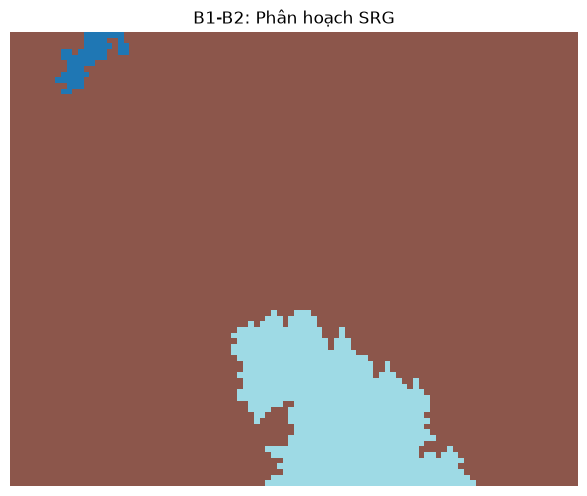

B3 — Số pixel khác sau remap (tie=raster): 0
B3 — Số pixel khác sau remap (tie=insertion): 0
B3 — Số pixel khác sau remap (ảnh phẳng, insertion): 52


{'raster': 0, 'insertion': 0, 'insertion_flat': 52}

In [23]:
def test_partition_and_region_count():
    """B1, B2: mọi pixel được gán nhãn và số vùng bằng số seed."""
    rng = np.random.default_rng(7)
    img = rng.random((80, 100), dtype=np.float64)
    seeds = [(10, 10), (10, 85), (65, 50)]
    labels, boundary = srg(img, seeds)

    assert (labels >= 0).all()
    assert len(np.unique(labels)) == len(seeds)
    print("B1 — Phân hoạch đầy đủ:", bool((labels >= 0).all()))
    print("B2 — Số vùng:", len(np.unique(labels)), "| số seed:", len(seeds))
    save_labels(labels, "B1-B2: Phân hoạch SRG", "b_kiem_chung_phan_hoach.png")
    return img, seeds, labels


def test_seed_order(img, seeds):
    """B3: đảo seed rồi remap nhãn về thứ tự ban đầu."""
    n = len(seeds)
    results = {}
    for tie in ("raster", "insertion"):
        labels_a, _ = srg(img, seeds, stale="lazy", tie=tie)
        labels_b, _ = srg(img, seeds[::-1], stale="lazy", tie=tie)
        labels_b_remapped = remap_labels(labels_b, list(range(n - 1, -1, -1)))
        different = int(np.count_nonzero(labels_a != labels_b_remapped))
        results[tie] = different
        print(f"B3 — Số pixel khác sau remap (tie={tie}):", different)

    # Trường hợp nhiều đồng hạng: ảnh phẳng có thể làm insertion phụ thuộc thứ tự seed.
    flat = np.full(img.shape, 0.5, dtype=np.float64)
    flat_a, _ = srg(flat, seeds, stale="frozen", tie="insertion")
    flat_b, _ = srg(flat, seeds[::-1], stale="frozen", tie="insertion")
    flat_b = remap_labels(flat_b, list(range(n - 1, -1, -1)))
    results["insertion_flat"] = int(np.count_nonzero(flat_a != flat_b))
    print("B3 — Số pixel khác sau remap (ảnh phẳng, insertion):",
          results["insertion_flat"])
    return results




img_b, seeds_b, _ = test_partition_and_region_count()
test_seed_order(img_b, seeds_b)

#### KIỂM CHỨNG B5 — Tie-breaking trên ảnh phẳng (insertion, raster, random)

**Prompt AI** — Người 5 · công cụ: Antigravity IDE · ngày 11/11/2026
> Chạy srg trên ảnh phẳng 101×101 với 2 hạt giống đối xứng qua 3 quy tắc
> phá hòa (insertion, raster, random). Thống kê kích thước vùng, số pixel
> khác nhau và lưu hình so sánh ket_qua/b_so_sanh_tie.png.

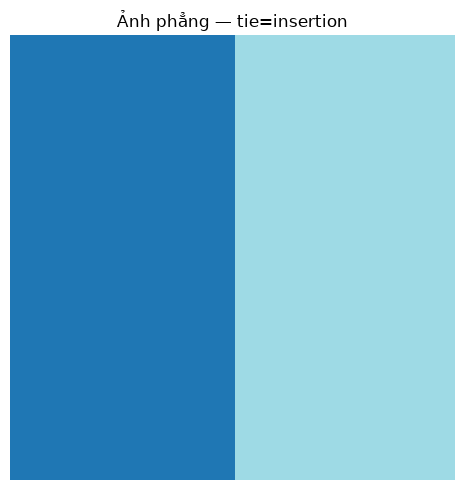

B5 — tie=insertion: kích thước vùng [5151, 5050]


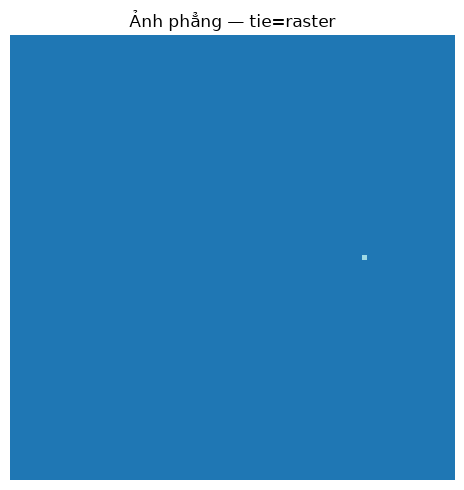

B5 — tie=raster: kích thước vùng [10200, 1]


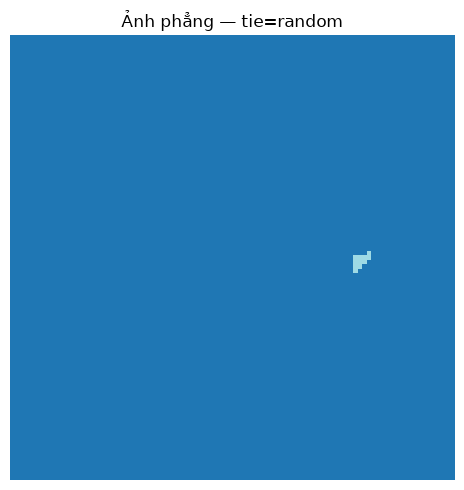

B5 — tie=random: kích thước vùng [10190, 11]
Khác biệt insertion vs raster: 5049 pixel
Khác biệt insertion vs random: 5039 pixel
Khác biệt raster vs random: 10 pixel


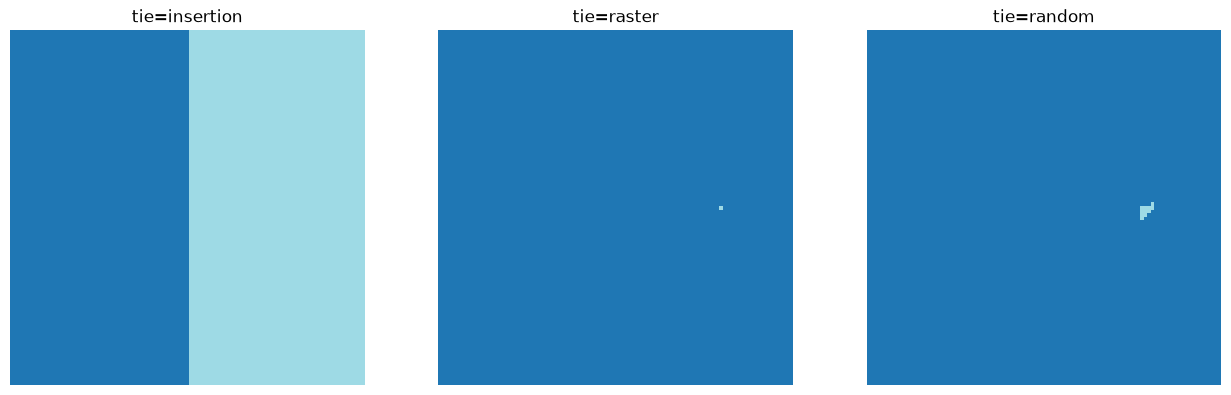

{('insertion', 'raster'): 5049,
 ('insertion', 'random'): 5039,
 ('raster', 'random'): 10}

In [24]:
def test_flat_ties():
    """B5: ảnh phẳng, mọi delta bằng 0 nên tie-breaking quyết định hình dạng."""
    img = np.full((101, 101), 0.5, dtype=np.float64)
    seeds = [(50, 20), (50, 80)]
    results = {}
    for tie in ("insertion", "raster", "random"):
        labels, boundary = srg(img, seeds, stale="frozen", tie=tie)
        results[tie] = labels
        save_labels(labels, f"Ảnh phẳng — tie={tie}", f"b_flat_tie_{tie}.png")
        print(f"B5 — tie={tie}: kích thước vùng",
              np.bincount(labels.ravel(), minlength=2).tolist())

    comparisons = {}
    for a, b in (("insertion", "raster"),
                 ("insertion", "random"),
                 ("raster", "random")):
        diff = int(np.count_nonzero(results[a] != results[b]))
        comparisons[(a, b)] = diff
        print(f"Khác biệt {a} vs {b}: {diff} pixel")
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, tie in zip(axes, ("insertion", "raster", "random")):
        show_labels(ax, results[tie], f"tie={tie}")
    fig.tight_layout()
    fig.savefig(OUT / "b_so_sanh_tie.png", dpi=150)
    plt.show()
    return comparisons




test_flat_ties()

#### THÍ NGHIỆM B1 — Cặp xử lý phần tử cũ: Lazy vs Frozen theo độ dốc sáng

**Prompt AI** — Người 5 · công cụ: Antigravity IDE · ngày 11/11/2026
> Quét độ mạnh dải sáng dọc (ramp) từ 0.0 đến 0.8 trên ảnh hai vùng chênh 0.2.
> Dùng _srg_engine đo độ chính xác, số lần đẩy lại (requeues) và kích thước
> heap cực đại giữa stale="lazy" và stale="frozen". Vẽ 2 đồ thị lưu vào
> ket_qua/b_lazy_frozen_quetch.png.

ramp=0.00 | chính xác lazy=1.000 frozen=1.000 | pixel khác=   0 | lazy đẩy lại=10108 | heap max lazy=2376 frozen=1937
ramp=0.05 | chính xác lazy=1.000 frozen=1.000 | pixel khác=   0 | lazy đẩy lại=10363 | heap max lazy=2423 frozen=1359
ramp=0.10 | chính xác lazy=1.000 frozen=1.000 | pixel khác=   0 | lazy đẩy lại=10144 | heap max lazy=1761 frozen=1485
ramp=0.15 | chính xác lazy=1.000 frozen=1.000 | pixel khác=   5 | lazy đẩy lại=10640 | heap max lazy=1275 frozen=1140
ramp=0.20 | chính xác lazy=0.994 frozen=0.943 | pixel khác= 512 | lazy đẩy lại=10611 | heap max lazy=1061 frozen=1002
ramp=0.25 | chính xác lazy=0.950 frozen=0.906 | pixel khác=1126 | lazy đẩy lại=10566 | heap max lazy=1011 frozen=904
ramp=0.30 | chính xác lazy=0.932 frozen=0.821 | pixel khác=1274 | lazy đẩy lại=10530 | heap max lazy=949 frozen=1035


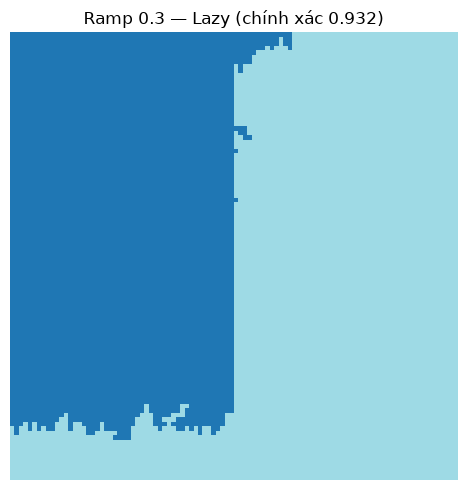

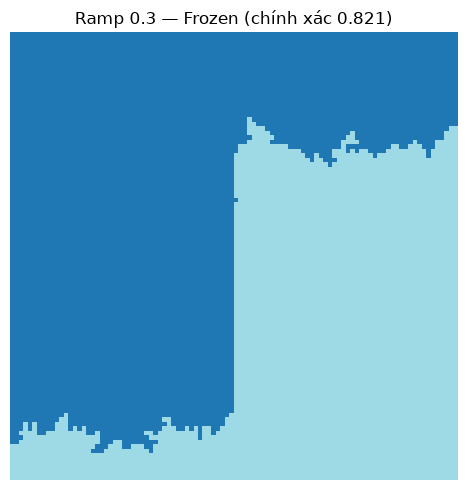

ramp=0.35 | chính xác lazy=0.807 frozen=0.784 | pixel khác= 232 | lazy đẩy lại=9323 | heap max lazy=923 frozen=1043
ramp=0.40 | chính xác lazy=0.808 frozen=0.754 | pixel khác= 539 | lazy đẩy lại=9580 | heap max lazy=897 frozen=979
ramp=0.45 | chính xác lazy=0.772 frozen=0.715 | pixel khác= 570 | lazy đẩy lại=9393 | heap max lazy=819 frozen=941
ramp=0.50 | chính xác lazy=0.739 frozen=0.695 | pixel khác= 446 | lazy đẩy lại=9629 | heap max lazy=807 frozen=798
ramp=0.55 | chính xác lazy=0.681 frozen=0.681 | pixel khác=  47 | lazy đẩy lại=9397 | heap max lazy=929 frozen=859
ramp=0.60 | chính xác lazy=0.661 frozen=0.666 | pixel khác= 111 | lazy đẩy lại=9588 | heap max lazy=804 frozen=954
ramp=0.65 | chính xác lazy=0.653 frozen=0.650 | pixel khác=  34 | lazy đẩy lại=9487 | heap max lazy=762 frozen=952
ramp=0.70 | chính xác lazy=0.653 frozen=0.644 | pixel khác=  89 | lazy đẩy lại=9369 | heap max lazy=767 frozen=895
ramp=0.75 | chính xác lazy=0.657 frozen=0.636 | pixel khác= 206 | lazy đẩy lại=

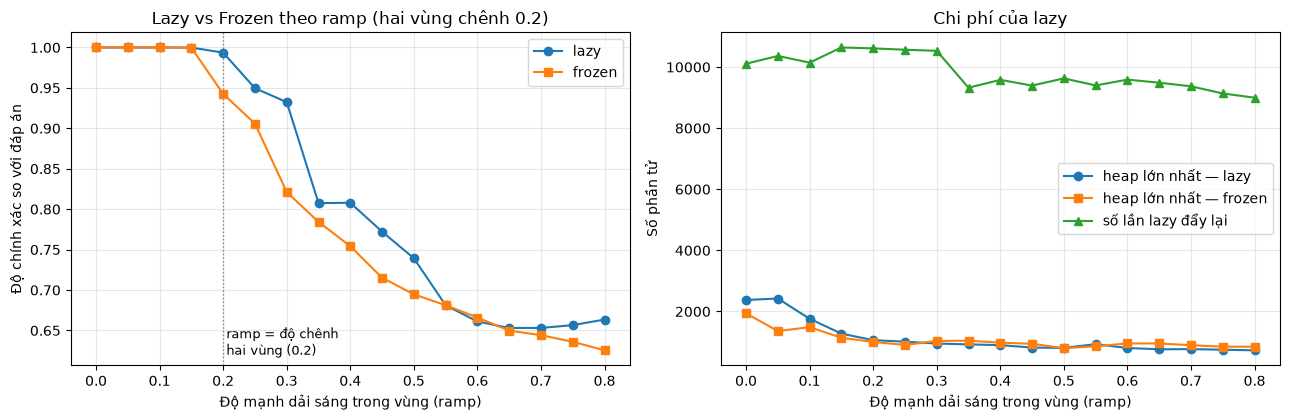

[(np.float64(0.0), 1.0, 1.0, 0, 10108, 2376, 1937),
 (np.float64(0.05), 1.0, 1.0, 0, 10363, 2423, 1359),
 (np.float64(0.1), 1.0, 1.0, 0, 10144, 1761, 1485),
 (np.float64(0.15), 0.9999, 0.9996, 5, 10640, 1275, 1140),
 (np.float64(0.2), 0.9936, 0.9426, 512, 10611, 1061, 1002),
 (np.float64(0.25), 0.9496, 0.9058, 1126, 10566, 1011, 904),
 (np.float64(0.3), 0.9324, 0.8212, 1274, 10530, 949, 1035),
 (np.float64(0.35), 0.8075, 0.7843, 232, 9323, 923, 1043),
 (np.float64(0.4), 0.8079, 0.7542, 539, 9580, 897, 979),
 (np.float64(0.45), 0.7722, 0.7152, 570, 9393, 819, 941),
 (np.float64(0.5), 0.7393, 0.6947, 446, 9629, 807, 798),
 (np.float64(0.55), 0.6811, 0.6812, 47, 9397, 929, 859),
 (np.float64(0.6), 0.6611, 0.666, 111, 9588, 804, 954),
 (np.float64(0.65), 0.6531, 0.6497, 34, 9487, 762, 952),
 (np.float64(0.7), 0.6531, 0.6442, 89, 9369, 767, 895),
 (np.float64(0.75), 0.6566, 0.636, 206, 9135, 748, 848),
 (np.float64(0.8), 0.6635, 0.6254, 381, 8996, 727, 846)]

In [25]:
def test_lazy_frozen():
    """Thí nghiệm lazy vs frozen: hai vùng chênh 0.2, mỗi vùng có dải sáng dần theo chiều dọc.

    Biết đáp án nên đo được độ chính xác. Quét độ mạnh của dải sáng (ramp) từ 0 tới 0.8.
    """
    h, w = 100, 100
    truth = np.zeros((h, w), dtype=np.int32)
    truth[:, w // 2:] = 1
    seeds = [(50, 25), (50, 75)]
    noise = 0.02 * np.random.default_rng(3).normal(size=(h, w))
    ramps = np.round(np.arange(0.0, 0.81, 0.05), 2)
    rows = []
    for ramp in ramps:
        img = np.where(truth == 0, 0.4, 0.6) + ramp * np.linspace(-0.5, 0.5, h)[:, None] + noise
        img = np.clip(img, 0.0, 1.0)
        lazy, _, _, st_l = _srg_engine(img, seeds, stale="lazy", tie="insertion")
        frozen, _, _, st_f = _srg_engine(img, seeds, stale="frozen", tie="insertion")
        rows.append((ramp, float((lazy == truth).mean()), float((frozen == truth).mean()),
                     int((lazy != frozen).sum()), st_l["requeues"],
                     st_l["max_heap_size"], st_f["max_heap_size"]))
        print("ramp={:.2f} | chính xác lazy={:.3f} frozen={:.3f} | pixel khác={:4d} | "
              "lazy đẩy lại={} | heap max lazy={} frozen={}".format(*rows[-1]))
        if abs(ramp - 0.3) < 1e-9:
            plt.imsave(IMG_DIR / "b_hai_vung_ramp03.png", img, cmap="gray", vmin=0, vmax=1)
            save_labels(lazy, f"Ramp 0.3 — Lazy (chính xác {rows[-1][1]:.3f})", "b_gradient_lazy.png")
            save_labels(frozen, f"Ramp 0.3 — Frozen (chính xác {rows[-1][2]:.3f})", "b_gradient_frozen.png")

    r = np.array(rows)
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
    axs[0].plot(r[:, 0], r[:, 1], "o-", label="lazy")
    axs[0].plot(r[:, 0], r[:, 2], "s-", label="frozen")
    axs[0].axvline(0.2, color="gray", ls=":", lw=1)
    axs[0].text(0.205, 0.62, "ramp = độ chênh\nhai vùng (0.2)", fontsize=9)
    axs[0].set_xlabel("Độ mạnh dải sáng trong vùng (ramp)")
    axs[0].set_ylabel("Độ chính xác so với đáp án")
    axs[0].set_title("Lazy vs Frozen theo ramp (hai vùng chênh 0.2)")
    axs[0].grid(alpha=0.3)
    axs[0].legend()
    axs[1].plot(r[:, 0], r[:, 5], "o-", label="heap lớn nhất — lazy")
    axs[1].plot(r[:, 0], r[:, 6], "s-", label="heap lớn nhất — frozen")
    axs[1].plot(r[:, 0], r[:, 4], "^-", label="số lần lazy đẩy lại")
    axs[1].set_xlabel("Độ mạnh dải sáng trong vùng (ramp)")
    axs[1].set_ylabel("Số phần tử")
    axs[1].set_title("Chi phí của lazy")
    axs[1].grid(alpha=0.3)
    axs[1].legend()
    fig.tight_layout()
    fig.savefig(OUT / "b_lazy_frozen_quetch.png", dpi=130)
    plt.show()
    return rows




test_lazy_frozen()

#### THÍ NGHIỆM B2 — Ảnh hưởng của lượng tử hóa mức xám tới Tie-breaking

**Prompt AI** — Người 5 · công cụ: Antigravity IDE · ngày 11/11/2026
> Quét số mức lượng tử hóa mức xám L trong [256, 128, 64, 32, 16, 8, 4]
> (lấy trung bình trên 6 ảnh nhiễu), đo tỉ lệ pixel khác nhãn giữa insertion
> với raster và random. Vẽ biểu đồ thang log2 lưu vào ket_qua/b_tie_luong_tu.png.

Mức xám = 256 | tỉ lệ pixel khác (trung bình 6 ảnh): insertion vs raster = 0.02% | insertion vs random = 0.02%
Mức xám = 128 | tỉ lệ pixel khác (trung bình 6 ảnh): insertion vs raster = 0.07% | insertion vs random = 0.08%
Mức xám =  64 | tỉ lệ pixel khác (trung bình 6 ảnh): insertion vs raster = 2.86% | insertion vs random = 0.55%
Mức xám =  32 | tỉ lệ pixel khác (trung bình 6 ảnh): insertion vs raster = 2.61% | insertion vs random = 0.67%
Mức xám =  16 | tỉ lệ pixel khác (trung bình 6 ảnh): insertion vs raster = 8.69% | insertion vs random = 7.36%
Mức xám =   8 | tỉ lệ pixel khác (trung bình 6 ảnh): insertion vs raster = 26.08% | insertion vs random = 7.32%
Mức xám =   4 | tỉ lệ pixel khác (trung bình 6 ảnh): insertion vs raster = 20.33% | insertion vs random = 18.10%


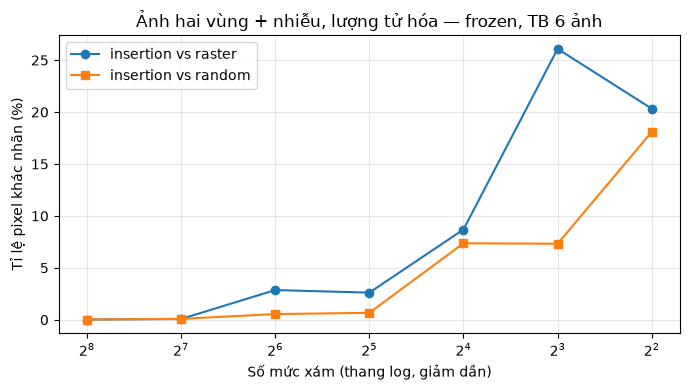

[(256, 0.00023333333333333333, 0.00023333333333333333),
 (128, 0.0007333333333333333, 0.00085),
 (64, 0.028583333333333332, 0.005483333333333333),
 (32, 0.026116666666666667, 0.006666666666666667),
 (16, 0.08688333333333333, 0.07361666666666668),
 (8, 0.26084999999999997, 0.07321666666666667),
 (4, 0.20326666666666668, 0.1809666666666667)]

In [26]:
def test_tie_quantization(n_anh=6):
    """Đồng hạng theo số mức xám: ảnh càng ít mức xám thì càng nhiều delta bằng nhau,
    quy tắc phá hòa càng làm đổi kết quả. Lấy trung bình trên n_anh ảnh nhiễu khác nhau."""
    h, w = 100, 100
    seeds = [(50, 25), (50, 75), (20, 50)]
    base = np.where(np.arange(w)[None, :] < w // 2, 0.4, 0.6) * np.ones((h, 1))
    levels = [256, 128, 64, 32, 16, 8, 4]
    rows = []
    for L in levels:
        d_ir, d_ia = [], []
        for sd in range(n_anh):
            goc = np.clip(base + 0.08 * np.random.default_rng(sd).normal(size=(h, w)), 0.0, 1.0)
            img = np.round(goc * (L - 1)) / (L - 1)
            kq = {t: srg(img, seeds, stale="frozen", tie=t)[0] for t in ("insertion", "raster", "random")}
            d_ir.append(float((kq["insertion"] != kq["raster"]).mean()))
            d_ia.append(float((kq["insertion"] != kq["random"]).mean()))
        rows.append((L, float(np.mean(d_ir)), float(np.mean(d_ia))))
        print(f"Mức xám = {L:3d} | tỉ lệ pixel khác (trung bình {n_anh} ảnh): "
              f"insertion vs raster = {rows[-1][1]:.2%} | insertion vs random = {rows[-1][2]:.2%}")
    r = np.array(rows)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(r[:, 0], 100 * r[:, 1], "o-", label="insertion vs raster")
    ax.plot(r[:, 0], 100 * r[:, 2], "s-", label="insertion vs random")
    ax.set_xscale("log", base=2)
    ax.invert_xaxis()
    ax.set_xlabel("Số mức xám (thang log, giảm dần)")
    ax.set_ylabel("Tỉ lệ pixel khác nhãn (%)")
    ax.set_title(f"Ảnh hai vùng + nhiễu, lượng tử hóa — frozen, TB {n_anh} ảnh")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT / "b_tie_luong_tu.png", dpi=130)
    plt.show()
    return rows




test_tie_quantization()

#### GIẢI THÍCH CƠ CHẾ — Tie-breaking, Lazy vs Frozen & Lượng tử hóa

**Prompt AI** — Người 5 · công cụ: Antigravity IDE · ngày 11/11/2026
> Soạn văn bản giải thích cơ chế B5 (hình dạng vùng theo quy tắc phá hòa),
> B3 (phụ thuộc thứ tự seed khi đồng hạng), cơ chế Lazy vs Frozen theo 3 ý
> và hiện tượng đồng hạng tăng khi giảm số mức xám.

In [27]:
GIAI_THICH = """
===== GIẢI THÍCH =====
B5 — hình dạng trên ảnh phẳng (mọi delta = 0, chỉ quy tắc phá hòa quyết định):
  - insertion: phần tử đẩy vào trước được lấy ra trước, nên cả hai vùng lớn đều nhau như
    duyệt theo chiều rộng. Hai vùng gặp nhau ở giữa hai hạt giống, ranh giới là đường
    thẳng đứng (5151 / 5050 pixel).
  - raster: lấy pixel có row*W + col nhỏ nhất. Vùng 0 có láng giềng ở hàng trên với khóa
    nhỏ hơn nên chiếm hết các hàng phía trên, rồi bao vây luôn hạt giống của vùng 1.
    Vùng 1 chỉ còn đúng hạt giống (10200 / 1 pixel).
  - random: khóa ngẫu nhiên gán lúc đẩy vào heap. Các phần tử còn lại trong heap có khóa
    ngày càng lớn, nên phần tử mới đẩy vào thường nhỏ hơn và được lấy ra ngay. Vùng nào
    đang lớn thì tiếp tục lớn, gần giống duyệt theo chiều sâu, nên một vùng chiếm gần hết.
B3 — trên ảnh nhiễu số thực, đảo thứ tự hạt giống cho 0 pixel khác: thứ tự nhận chỉ do
  delta quyết định. Trên ảnh phẳng thì 52 pixel khác, vì khi delta bằng nhau thì khóa
  insertion phụ thuộc thứ tự hạt giống được đẩy vào. Đây là hạn chế đề nêu ở mục đồng hạng.

Thí nghiệm lazy vs frozen:
(1) Đại lượng tính khác: lazy so I(x) với trung bình HIỆN TẠI của vùng; frozen so với giá
    trị của hạt giống, không bao giờ cập nhật.
(2) Ở bước: tính delta khi đẩy vào heap và khi lấy ra (lazy tính lại, đẩy lại nếu đã cũ).
(3) Vì sao: khi trong vùng có dải sáng, pixel xa hạt giống lệch khỏi giá trị hạt giống một
    khoảng ramp/2. Khi ramp/2 tiến gần nửa độ chênh hai vùng, delta tới hạt giống của
    chính nó bằng delta tới vùng bên kia, nên frozen bắt đầu gán nhầm (độ chính xác rơi từ
    ramp khoảng 0.2). Lazy cập nhật trung bình khi vùng lớn dần vào dải sáng nên theo
    được lâu hơn (ở ramp 0.3: lazy 0.932, frozen 0.821). Đổi lại, lazy phải đẩy lại
    khoảng 9–10 nghìn phần tử vào heap, gần bằng số pixel của ảnh (10 nghìn).
    Khi ramp quá lớn (> 0.5) cả hai đều sai vì trong vùng còn chênh nhiều hơn giữa hai vùng.

Thí nghiệm đồng hạng theo số mức xám:
  Ảnh càng ít mức xám thì càng nhiều pixel có cùng delta, nên khóa phá hòa quyết định
  nhiều lần nhận hơn. Tỉ lệ pixel khác giữa các quy tắc tăng từ khoảng 0.02% (256 mức)
  lên 18–26% (4–8 mức). Đường không tăng đều tuyệt đối vì vị trí đồng hạng phụ thuộc
  cách làm tròn, nên đã lấy trung bình trên nhiều ảnh nhiễu.
"""




print(GIAI_THICH)


===== GIẢI THÍCH =====
B5 — hình dạng trên ảnh phẳng (mọi delta = 0, chỉ quy tắc phá hòa quyết định):
  - insertion: phần tử đẩy vào trước được lấy ra trước, nên cả hai vùng lớn đều nhau như
    duyệt theo chiều rộng. Hai vùng gặp nhau ở giữa hai hạt giống, ranh giới là đường
    thẳng đứng (5151 / 5050 pixel).
  - raster: lấy pixel có row*W + col nhỏ nhất. Vùng 0 có láng giềng ở hàng trên với khóa
    nhỏ hơn nên chiếm hết các hàng phía trên, rồi bao vây luôn hạt giống của vùng 1.
    Vùng 1 chỉ còn đúng hạt giống (10200 / 1 pixel).
  - random: khóa ngẫu nhiên gán lúc đẩy vào heap. Các phần tử còn lại trong heap có khóa
    ngày càng lớn, nên phần tử mới đẩy vào thường nhỏ hơn và được lấy ra ngay. Vùng nào
    đang lớn thì tiếp tục lớn, gần giống duyệt theo chiều sâu, nên một vùng chiếm gần hết.
B3 — trên ảnh nhiễu số thực, đảo thứ tự hạt giống cho 0 pixel khác: thứ tự nhận chỉ do
  delta quyết định. Trên ảnh phẳng thì 52 pixel khác, vì khi delta bằng nhau thì khóa
  insertion phụ th

## B.4 Kiểm chứng B4 và thí nghiệm SRG vs Region Growing (Người 4)

**Prompt AI** — Người 4 · công cụ: Antigravity IDE · ngày 10/11/2026
> Viết phần import, hằng đường dẫn, hàm tạo ảnh hai vùng chênh delta kèm dải
> sáng dọc (ramp=0.15) và nhiễu Gauss (noise=0.03), cùng các hàm tính độ chính
> xác (do_chinh_xac) và tỉ lệ rò vùng (ti_le_ro).

In [28]:
import os

import matplotlib.pyplot as plt
import numpy as np


HERE = os.getcwd()
OUT = os.path.join(HERE, "ket_qua")
ANH = os.path.join(HERE, "anh")
os.makedirs(OUT, exist_ok=True)
os.makedirs(ANH, exist_ok=True)

# ------------------------------------------------------------------ ảnh thử
# Hai vùng trái/phải chênh nhau delta, cộng một dải sáng dần theo chiều dọc (ramp)
# và nhiễu Gauss. Vì tự tạo nên biết đáp án (truth) và đo được độ chính xác.
H = W = 128
TRUTH = np.zeros((H, W), dtype=np.int32)
TRUTH[:, W // 2:] = 1
SEEDS = [(64, 20), (64, 108)]          # hạt giống 0 ở vùng trái, 1 ở vùng phải
RAMP, NOISE = 0.15, 0.03


def tao_anh(delta, ramp=RAMP, noise=NOISE, seed=1):
    rng = np.random.default_rng(seed)
    base = np.where(TRUTH == 0, 0.4, 0.4 + delta)
    doc = ramp * np.linspace(-0.5, 0.5, H)[:, None]
    return np.clip(base + doc + noise * rng.normal(size=(H, W)), 0.0, 1.0)


def do_chinh_xac(labels):
    """Tỉ lệ pixel có nhãn đúng với đáp án (pixel -1 tính là sai)."""
    return float((labels == TRUTH).mean())


def ti_le_ro(labels):
    """Tỉ lệ pixel của vùng phải bị vùng 0 (vùng trái) chiếm."""
    return float(((labels == 0) & (TRUTH == 1)).sum() / (TRUTH == 1).sum())


def luu_anh(img, ten):
    plt.imsave(os.path.join(ANH, ten), img, cmap="gray", vmin=0, vmax=1)


DELTA = 0.2
img = tao_anh(DELTA)
luu_anh(img, "b_hai_vung_delta02.png")

#### KIỂM CHỨNG B4 — Đối chiếu Region Growing (stack/queue) và SRG

**Prompt AI** — Người 4 · công cụ: Antigravity IDE · ngày 10/11/2026
> Chạy region_growing_classic (order="stack" và "queue", T=0.08) cùng srg
> trên ảnh hai vùng (delta=0.2). Thống kê số pixel khác nhau giữa các cặp,
> tỉ lệ pixel chưa gán nhãn, và vẽ lưới 1×4 lưu vào ket_qua/b4_rg_vs_srg.png.

B4. Đối chiếu với Region Growing (ảnh hai vùng, delta = 0.2, T = 0.08)
  stack vs queue:  2891 pixel khác nhau (17.6% ảnh)
  stack vs srg  :  3198 pixel khác nhau (19.5% ảnh)
  queue vs srg  :  2430 pixel khác nhau (14.8% ảnh)
  Pixel chưa gán nhãn: stack = 19.5%, queue = 14.8%, srg = 0.0%


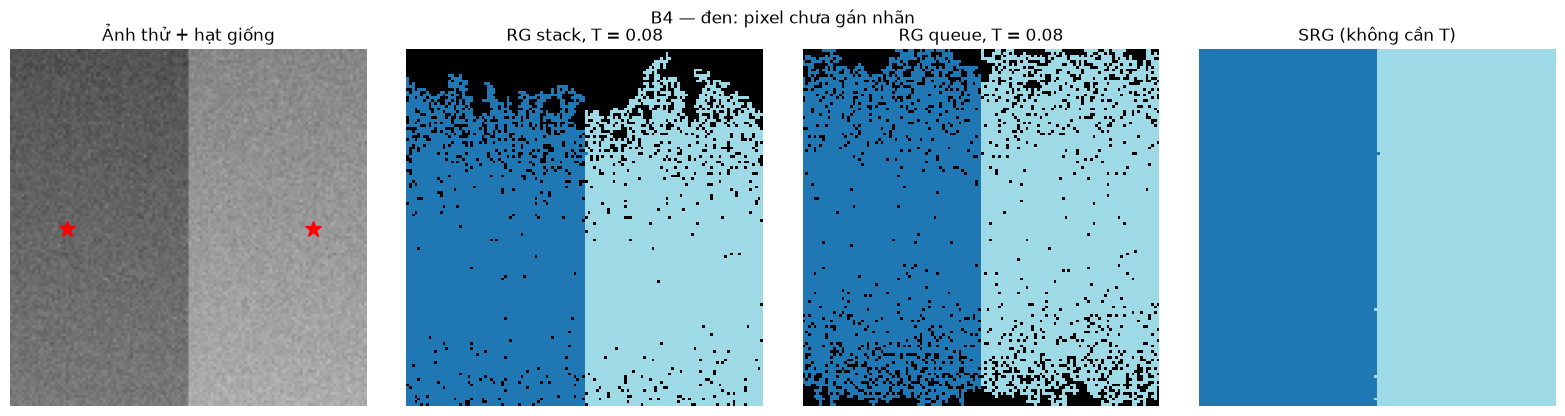

In [29]:
print("=" * 66)
print(f"B4. Đối chiếu với Region Growing (ảnh hai vùng, delta = {DELTA}, T = 0.08)")
T_B4 = 0.08
rg_stack = region_growing_classic(img, SEEDS, T_B4, order="stack")
rg_queue = region_growing_classic(img, SEEDS, T_B4, order="queue")
lab_srg, bien = srg(img, SEEDS)
cap = [("stack", "queue", rg_stack, rg_queue),
       ("stack", "srg", rg_stack, lab_srg),
       ("queue", "srg", rg_queue, lab_srg)]
for a, b, la, lb in cap:
    print(f"  {a:5s} vs {b:5s}: {int((la != lb).sum()):5d} pixel khác nhau "
          f"({(la != lb).mean():.1%} ảnh)")
print(f"  Pixel chưa gán nhãn: stack = {(rg_stack < 0).mean():.1%}, "
      f"queue = {(rg_queue < 0).mean():.1%}, srg = {(lab_srg < 0).mean():.1%}")

fig, axs = plt.subplots(1, 4, figsize=(16, 4.2))
axs[0].imshow(img, cmap="gray", vmin=0, vmax=1)
axs[0].plot([c for _, c in SEEDS], [r for r, _ in SEEDS], "r*", ms=12)
axs[0].set_title("Ảnh thử + hạt giống")
axs[0].axis("off")
show_labels(axs[1], rg_stack, f"RG stack, T = {T_B4}")
show_labels(axs[2], rg_queue, f"RG queue, T = {T_B4}")
show_labels(axs[3], lab_srg, "SRG (không cần T)")
fig.suptitle("B4 — đen: pixel chưa gán nhãn")
fig.tight_layout()
fig.savefig(os.path.join(OUT, "b4_rg_vs_srg.png"), dpi=110)
plt.show()

#### MINH HỌA TIẾN TRÌNH — srg_step_frames (8 mốc thời gian)

**Prompt AI** — Người 4 · công cụ: Antigravity IDE · ngày 10/11/2026
> Dùng srg_step_frames chụp 8 frame trong quá trình lan vùng của SRG,
> kiểm tra frame cuối trùng khớp srg và lưu hình ket_qua/b_srg_tien_trinh.png.

srg_step_frames: tỉ lệ pixel đã có nhãn ở từng frame: [0.125, 0.25, 0.375, 0.5, 0.625, 0.75, 0.875, 1.0]
  Frame cuối trùng kết quả srg: True


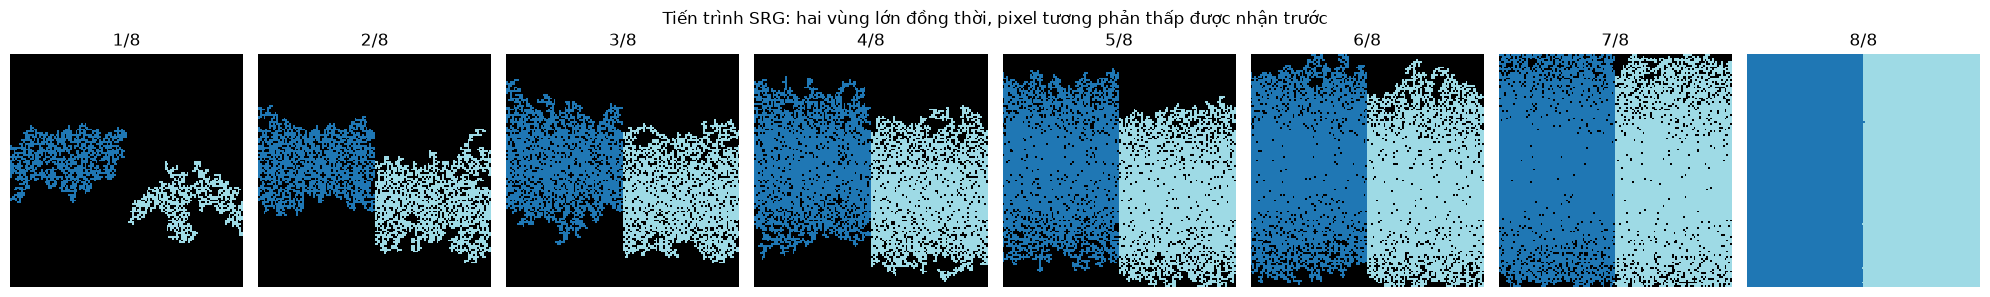

In [30]:
print("=" * 66)
frames = srg_step_frames(img, SEEDS, n_frames=8)
print("srg_step_frames: tỉ lệ pixel đã có nhãn ở từng frame:",
      [round(float((f >= 0).mean()), 3) for f in frames])
print("  Frame cuối trùng kết quả srg:", bool((frames[-1] == lab_srg).all()))
fig, axs = plt.subplots(1, 8, figsize=(20, 3))
for k, (ax, f) in enumerate(zip(axs, frames), 1):
    show_labels(ax, f, f"{k}/8")
fig.suptitle("Tiến trình SRG: hai vùng lớn đồng thời, pixel tương phản thấp được nhận trước")
fig.tight_layout()
fig.savefig(os.path.join(OUT, "b_srg_tien_trinh.png"), dpi=100)
plt.show()

#### 6.1 — Bằng chứng: RG phụ thuộc ngưỡng T vs SRG không cần T

**Prompt AI** — Người 4 · công cụ: Antigravity IDE · ngày 10/11/2026
> So sánh RG ở 3 mức ngưỡng T = [0.06, 0.12, 0.18] với SRG trên ảnh hai vùng.
> In độ chính xác, tỉ lệ chưa gán, tỉ lệ rò vùng và lưu ket_qua/b_bang_chung_rg_vs_srg.png.

6.1 Bằng chứng: RG phải dò đúng T, SRG thì không có T
  RG stack T = 0.06: chính xác = 0.587 | chưa gán = 41.3% | rò sang vùng phải = 0.0%
  RG stack T = 0.12: chính xác = 0.990 | chưa gán = 0.7% | rò sang vùng phải = 0.5%
  RG stack T = 0.18: chính xác = 0.496 | chưa gán = 13.8% | rò sang vùng phải = 73.3%
  SRG              : chính xác = 1.000


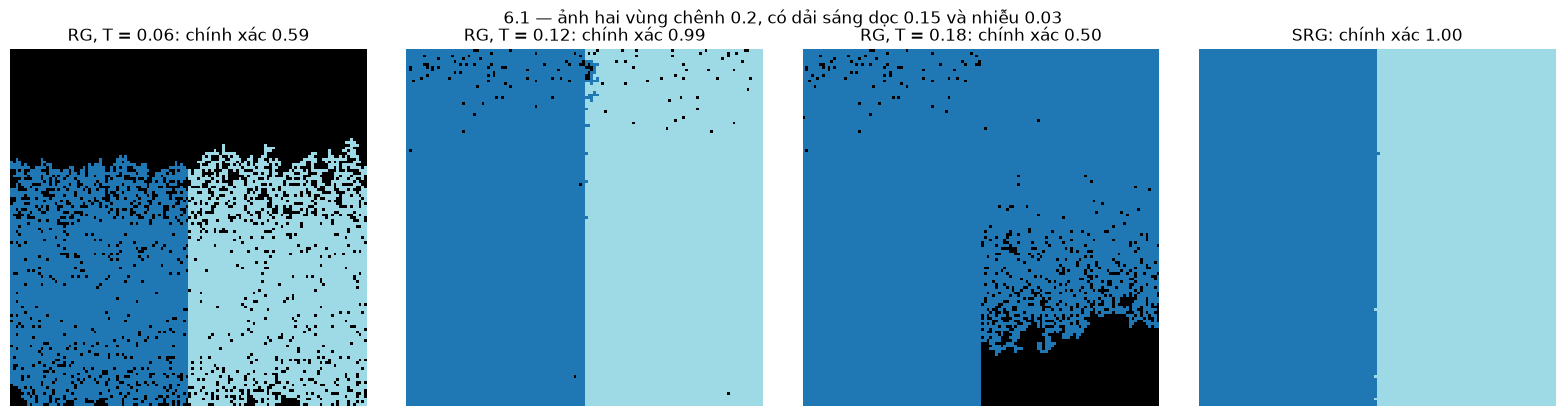

In [31]:
print("=" * 66)
print("6.1 Bằng chứng: RG phải dò đúng T, SRG thì không có T")
T_ds_61 = [0.06, 0.12, 0.18]
fig, axs = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, T in zip(axs, T_ds_61):
    lab = region_growing_classic(img, SEEDS, T, order="stack")
    print(f"  RG stack T = {T:.2f}: chính xác = {do_chinh_xac(lab):.3f} | "
          f"chưa gán = {(lab < 0).mean():.1%} | rò sang vùng phải = {ti_le_ro(lab):.1%}")
    show_labels(ax, lab, f"RG, T = {T}: chính xác {do_chinh_xac(lab):.2f}")
print(f"  SRG              : chính xác = {do_chinh_xac(lab_srg):.3f}")
show_labels(axs[3], lab_srg, f"SRG: chính xác {do_chinh_xac(lab_srg):.2f}")
fig.suptitle(f"6.1 — ảnh hai vùng chênh {DELTA}, có dải sáng dọc {RAMP} và nhiễu {NOISE}")
fig.tight_layout()
fig.savefig(os.path.join(OUT, "b_bang_chung_rg_vs_srg.png"), dpi=110)
plt.show()

#### 6.2a — Quét ngưỡng T × độ chênh delta giữa hai vùng

**Prompt AI** — Người 4 · công cụ: Antigravity IDE · ngày 10/11/2026
> Quét lưới 2 chiều giữa độ chênh delta trong [0.10, 0.40] và ngưỡng T trong
> [0.02, 0.40]. Vẽ heatmap độ chính xác của RG và đồ thị so sánh RG (T tốt nhất)
> với SRG, lưu vào ket_qua/b_quet_T_delta.png.

6.2a Quét ngưỡng T của RG theo độ chênh delta giữa hai vùng
  delta = 0.10: RG tốt nhất = 0.515 | khoảng T cho chính xác >= 0.95: không có       | SRG = 0.830
  delta = 0.15: RG tốt nhất = 0.804 | khoảng T cho chính xác >= 0.95: không có       | SRG = 0.994
  delta = 0.20: RG tốt nhất = 0.990 | khoảng T cho chính xác >= 0.95: [0.10, 0.12]   | SRG = 1.000
  delta = 0.25: RG tốt nhất = 0.999 | khoảng T cho chính xác >= 0.95: [0.10, 0.18]   | SRG = 1.000
  delta = 0.30: RG tốt nhất = 1.000 | khoảng T cho chính xác >= 0.95: [0.10, 0.22]   | SRG = 1.000
  delta = 0.35: RG tốt nhất = 1.000 | khoảng T cho chính xác >= 0.95: [0.10, 0.26]   | SRG = 1.000
  delta = 0.40: RG tốt nhất = 1.000 | khoảng T cho chính xác >= 0.95: [0.10, 0.32]   | SRG = 1.000


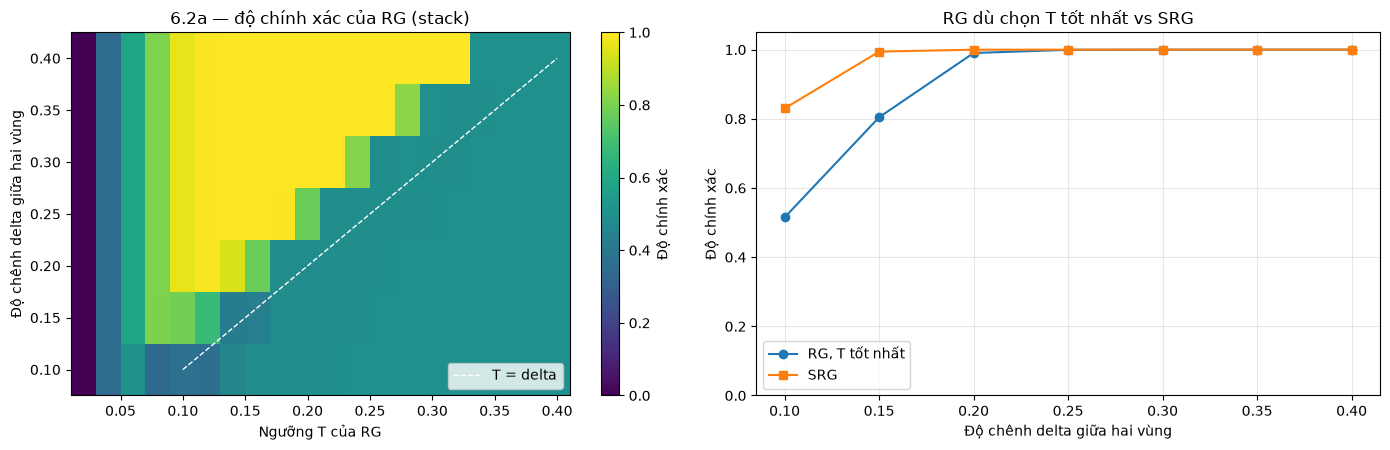

In [32]:
print("=" * 66)
print("6.2a Quét ngưỡng T của RG theo độ chênh delta giữa hai vùng")
deltas = np.round(np.arange(0.10, 0.41, 0.05), 2)
Ts = np.round(np.arange(0.02, 0.42, 0.02), 2)
acc = np.zeros((len(deltas), len(Ts)))
acc_srg = []
cua_so = []
for i, d in enumerate(deltas):
    im = tao_anh(d)
    for j, T in enumerate(Ts):
        acc[i, j] = do_chinh_xac(region_growing_classic(im, SEEDS, T, order="stack"))
    acc_srg.append(do_chinh_xac(srg(im, SEEDS)[0]))
    tot = Ts[acc[i] >= 0.95]
    cua_so.append((tot.min(), tot.max()) if len(tot) else None)
    cs = f"[{tot.min():.2f}, {tot.max():.2f}]" if len(tot) else "không có"
    print(f"  delta = {d:.2f}: RG tốt nhất = {acc[i].max():.3f} | "
          f"khoảng T cho chính xác >= 0.95: {cs:14s} | SRG = {acc_srg[-1]:.3f}")

fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axs[0]
im_ = ax.imshow(acc, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1,
                extent=[Ts[0] - 0.01, Ts[-1] + 0.01, deltas[0] - 0.025, deltas[-1] + 0.025])
ax.plot(deltas, deltas, "w--", lw=1, label="T = delta")
ax.set_xlabel("Ngưỡng T của RG")
ax.set_ylabel("Độ chênh delta giữa hai vùng")
ax.set_title("6.2a — độ chính xác của RG (stack)")
ax.legend(loc="lower right")
fig.colorbar(im_, ax=ax, label="Độ chính xác")
ax = axs[1]
ax.plot(deltas, acc.max(axis=1), "o-", label="RG, T tốt nhất")
ax.plot(deltas, acc_srg, "s-", label="SRG")
ax.set_xlabel("Độ chênh delta giữa hai vùng")
ax.set_ylabel("Độ chính xác")
ax.set_ylim(0, 1.05)
ax.set_title("RG dù chọn T tốt nhất vs SRG")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(OUT, "b_quet_T_delta.png"), dpi=110)
plt.show()

#### 6.2b — Độ nhạy vị trí hạt giống trên ảnh thực (oxford/boat)

**Prompt AI** — Người 4 · công cụ: Antigravity IDE · ngày 10/11/2026
> Đánh giá độ nhạy hạt giống bằng seed_sensitivity (20 lần thử, jitter = 2, 5, 10 px)
> cho RG (T=0.10) và SRG trên ảnh oxford/boat/img1 thu nhỏ (256×205) với 5 hạt giống.
> Vẽ bản đồ tần suất đổi nhãn lưu vào ket_qua/b_do_nhay_hat_giong.png.

6.2b Độ nhạy hạt giống trên ảnh thật (oxford/boat/img1 thu nhỏ 256 px, 20 lần thử)
  RG (T = 0.1): pixel có nhãn = 20.2% | kích thước vùng = [5712, 0, 1264, 307, 3334]
  SRG          : pixel có nhãn = 100.0% | kích thước vùng = [9547, 42, 2399, 495, 39997]
  jitter =  2 px: tỉ lệ pixel từng đổi nhãn  RG = 0.050 | SRG = 0.038
  jitter =  5 px: tỉ lệ pixel từng đổi nhãn  RG = 0.174 | SRG = 0.365
  jitter = 10 px: tỉ lệ pixel từng đổi nhãn  RG = 0.205 | SRG = 0.387


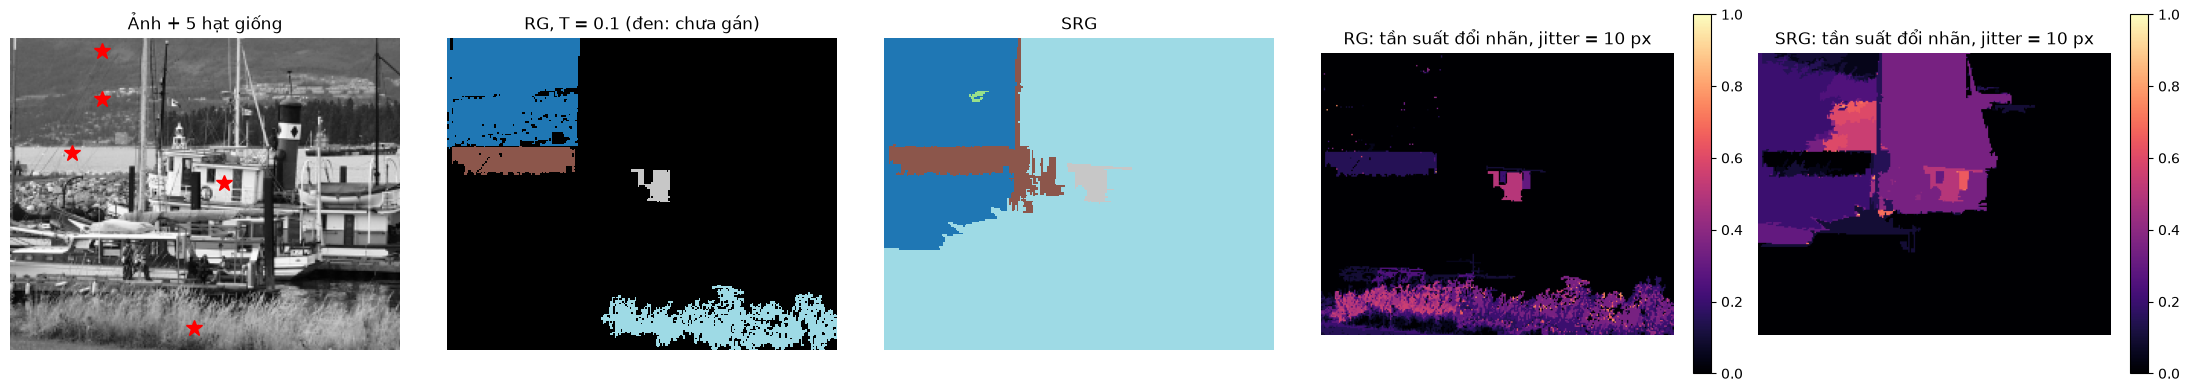

In [33]:
print("=" * 66)
print("6.2b Độ nhạy hạt giống trên ảnh thật (oxford/boat/img1 thu nhỏ 256 px, 20 lần thử)")
import cv2
boat, _ = load_oxford("boat", 1)
boat = cv2.resize(boat, (256, 205), interpolation=cv2.INTER_AREA)
# Hạt giống: trời, đồi tối, mặt nước, thân tàu trắng, cỏ
SEEDS_BOAT = [(8, 60), (40, 60), (75, 40), (95, 140), (190, 120)]
T_tot = 0.10
lab_rg_boat = region_growing_classic(boat, SEEDS_BOAT, T_tot)
lab_srg_boat, _ = srg(boat, SEEDS_BOAT)
print(f"  RG (T = {T_tot}): pixel có nhãn = {(lab_rg_boat >= 0).mean():.1%} | "
      f"kích thước vùng = {[int((lab_rg_boat == i).sum()) for i in range(len(SEEDS_BOAT))]}")
print(f"  SRG          : pixel có nhãn = {(lab_srg_boat >= 0).mean():.1%} | "
      f"kích thước vùng = {[int((lab_srg_boat == i).sum()) for i in range(len(SEEDS_BOAT))]}")
jitters = [2, 5, 10]
nhay_rg, nhay_srg = [], []
for j in jitters:
    f_rg = seed_sensitivity(boat, SEEDS_BOAT, lambda im, s: region_growing_classic(im, s, T_tot), 20, j)
    f_srg = seed_sensitivity(boat, SEEDS_BOAT, srg, 20, j)
    nhay_rg.append(float((f_rg > 0).mean()))
    nhay_srg.append(float((f_srg > 0).mean()))
    print(f"  jitter = {j:2d} px: tỉ lệ pixel từng đổi nhãn  RG = {nhay_rg[-1]:.3f} | SRG = {nhay_srg[-1]:.3f}")
    if j == 10:
        ban_do_rg, ban_do_srg = f_rg, f_srg

fig, axs = plt.subplots(1, 5, figsize=(22, 4.2))
axs[0].imshow(boat, cmap="gray", vmin=0, vmax=1)
axs[0].plot([c for _, c in SEEDS_BOAT], [r for r, _ in SEEDS_BOAT], "r*", ms=12)
axs[0].set_title("Ảnh + 5 hạt giống")
axs[0].axis("off")
show_labels(axs[1], lab_rg_boat, f"RG, T = {T_tot} (đen: chưa gán)")
show_labels(axs[2], lab_srg_boat, "SRG")
for ax, bd, ten in [(axs[3], ban_do_rg, "RG"), (axs[4], ban_do_srg, "SRG")]:
    m = ax.imshow(bd / 20, cmap="magma", vmin=0, vmax=1)
    ax.set_title(f"{ten}: tần suất đổi nhãn, jitter = 10 px")
    ax.axis("off")
    fig.colorbar(m, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "b_do_nhay_hat_giong.png"), dpi=100)
plt.show()

#### 6.2c — So sánh lân cận 4-connectivity vs 8-connectivity

**Prompt AI** — Người 4 · công cụ: Antigravity IDE · ngày 10/11/2026
> Kiểm tra khả năng lan vùng của SRG dọc theo đường chéo mảnh 1 pixel
> khi dùng connectivity=4 so với connectivity=8.

In [34]:
print("=" * 66)
print("6.2c Liên thông 4 vs 8 của SRG")
nen = tao_anh(0.0, ramp=0.0)               # nền đồng nhất 0.4 + nhiễu
duong = nen.copy()
rr = np.arange(10, 118)
duong[rr, rr] = 0.9                         # đường chéo mảnh 1 pixel
truth_duong = np.zeros_like(TRUTH)
truth_duong[rr, rr] = 1
seeds_c = [(64, 20), (10, 10)]              # hạt giống 1 nằm trên đường chéo
for conn in (4, 8):
    lab, _ = srg(duong, seeds_c, connectivity=conn)
    tren_duong = float((lab[rr, rr] == 1).mean())
    print(f"  connectivity = {conn}: tỉ lệ pixel đường chéo thuộc vùng 1 = {tren_duong:.3f} | "
          f"kích thước vùng 1 = {int((lab == 1).sum())} pixel")

6.2c Liên thông 4 vs 8 của SRG
  connectivity = 4: tỉ lệ pixel đường chéo thuộc vùng 1 = 0.009 | kích thước vùng 1 = 1 pixel
  connectivity = 8: tỉ lệ pixel đường chéo thuộc vùng 1 = 1.000 | kích thước vùng 1 = 108 pixel


#### 6.3 — Giải thích cơ chế (RG vs SRG)

**Prompt AI** — Người 4 · công cụ: Antigravity IDE · ngày 10/11/2026
> Soạn phần giải thích cơ chế khác biệt giữa RG và SRG theo 3 câu hỏi:
> đại lượng tính khác nhau, bước thực hiện, và lý giải kết quả thực nghiệm
> ở các mục B4, 6.1, 6.2a, 6.2b, 6.2c.

In [35]:
print("=" * 66)
print("""6.3 Giải thích
(1) Đại lượng tính khác:
    - RG quyết định nhận hay bỏ một pixel bằng phép so |I(q) − mu| <= T với một ngưỡng T
      cố định, và thứ tự xét do stack/queue quyết định.
    - SRG không có ngưỡng. Nó tính delta(x) = |I(x) − mean(A_i)| cho mọi pixel ở biên của
      mọi vùng, rồi luôn nhận pixel có delta nhỏ nhất toàn cục trước.
(2) Ở bước nào: bước chọn pixel kế tiếp và bước quyết định có nhận pixel hay không.
    Khởi tạo hạt giống và cập nhật trung bình vùng giữ nguyên.
(3) Vì sao ra đúng hiện tượng đã đo:
    - RG cần T đủ lớn để nuốt dải sáng dọc và nhiễu bên trong một vùng, nhưng phải nhỏ
      hơn độ chênh giữa hai vùng để không rò sang vùng kia. Vì vậy chỉ có một khoảng T
      dùng được, và khoảng đó hẹp lại khi delta giảm. Ở delta nhỏ thì khoảng này biến
      mất hẳn: không có T nào cho kết quả tốt (6.2a).
    - Ngoài ra RG chạy vùng 0 xong mới tới vùng 1. Khi T quá lớn, vùng 0 chiếm cả vùng
      phải trước khi vùng 1 kịp lớn, nên độ chính xác rơi về khoảng 0.5 (6.1).
    - Stack và queue cho kết quả khác nhau (B4) vì mu thay đổi trong lúc vùng lớn: duyệt
      theo thứ tự khác thì mu tại lúc xét cùng một pixel khác nhau.
    - SRG cho mọi vùng lớn đồng thời. Pixel ở ranh giới hai vùng có delta lớn với cả hai,
      nên bị xét sau cùng, khi phần lõi mỗi vùng đã được nhận. Do đó ranh giới tự rơi vào
      chỗ tương phản cao nhất mà không cần chọn ngưỡng. SRG chỉ sai khi dải sáng trong
      vùng lớn hơn độ chênh giữa hai vùng (delta = 0.10 < RAMP = 0.15).
    - Ở ảnh thật (6.2b), SRG có tỉ lệ pixel đổi nhãn cao hơn RG. Đây không phải vì RG ổn
      định hơn: RG để khoảng 80% ảnh không có nhãn, và các pixel đó giữ nhãn -1 dù hạt
      giống dịch đi đâu. SRG bắt buộc chia hết ảnh, nên khi một hạt giống trượt sang vùng
      khác thì ranh giới giữa các vùng dịch theo, kéo theo cả mảng pixel đổi nhãn. Đây
      đúng là hệ quả đề nêu: SRG bỏ ngưỡng T, nên toàn bộ độ khó chuyển sang việc đặt
      hạt giống.
    - Cũng ở ảnh này, vùng 1 (đồi tối) của RG rỗng: vùng 0 (trời) chạy trước và chiếm luôn
      hạt giống của vùng 1. Ở SRG vùng 1 vẫn còn (dù chỉ 42 pixel) vì mọi vùng lớn đồng
      thời, không vùng nào chiếm được hạt giống của vùng khác.
    - Liên thông 4 không đi qua được đường chéo mảnh 1 pixel vì hai pixel chéo nhau không
      kề nhau; liên thông 8 thì đi được (6.2c).""")
print("Hình đã lưu trong ket_qua/")

6.3 Giải thích
(1) Đại lượng tính khác:
    - RG quyết định nhận hay bỏ một pixel bằng phép so |I(q) − mu| <= T với một ngưỡng T
      cố định, và thứ tự xét do stack/queue quyết định.
    - SRG không có ngưỡng. Nó tính delta(x) = |I(x) − mean(A_i)| cho mọi pixel ở biên của
      mọi vùng, rồi luôn nhận pixel có delta nhỏ nhất toàn cục trước.
(2) Ở bước nào: bước chọn pixel kế tiếp và bước quyết định có nhận pixel hay không.
    Khởi tạo hạt giống và cập nhật trung bình vùng giữ nguyên.
(3) Vì sao ra đúng hiện tượng đã đo:
    - RG cần T đủ lớn để nuốt dải sáng dọc và nhiễu bên trong một vùng, nhưng phải nhỏ
      hơn độ chênh giữa hai vùng để không rò sang vùng kia. Vì vậy chỉ có một khoảng T
      dùng được, và khoảng đó hẹp lại khi delta giảm. Ở delta nhỏ thì khoảng này biến
      mất hẳn: không có T nào cho kết quả tốt (6.2a).
    - Ngoài ra RG chạy vùng 0 xong mới tới vùng 1. Khi T quá lớn, vùng 0 chiếm cả vùng
      phải trước khi vùng 1 kịp lớn, nên độ chính xác rơi về khoảng 0.

# Tài liệu tham khảo

1. C. Harris and M. Stephens, "A combined corner and edge detector," in *Proc. 4th Alvey Vision Conf.*, Manchester, UK, 1988, pp. 147–151.
2. T. Lindeberg, "Feature detection with automatic scale selection," *Int. J. Comput. Vis.*, vol. 30, no. 2, pp. 79–116, 1998.
3. K. Mikolajczyk and C. Schmid, "Scale & affine invariant interest point detectors," *Int. J. Comput. Vis.*, vol. 60, no. 1, pp. 63–86, 2004. doi: 10.1023/B:VISI.0000027790.02288.f2
4. M. Brown, R. Szeliski, and S. Winder, "Multi-image matching using multi-scale oriented patches," in *Proc. IEEE CVPR*, San Diego, CA, USA, 2005, vol. 1, pp. 510–517. doi: 10.1109/CVPR.2005.235
5. R. Adams and L. Bischof, "Seeded region growing," *IEEE Trans. Pattern Anal. Mach. Intell.*, vol. 16, no. 6, pp. 641–647, Jun. 1994. doi: 10.1109/34.295913
6. A. Mehnert and P. Jackway, "An improved seeded region growing algorithm," *Pattern Recognit. Lett.*, vol. 18, no. 10, pp. 1065–1071, 1997.
7. J. Shi and C. Tomasi, "Good features to track," in *Proc. IEEE CVPR*, Seattle, WA, USA, 1994, pp. 593–600.
8. K. Mikolajczyk, T. Tuytelaars, C. Schmid, A. Zisserman, J. Matas, F. Schaffalitzky, T. Kadir, and L. Van Gool, "A comparison of affine region detectors," *Int. J. Comput. Vis.*, vol. 65, no. 1/2, pp. 43–72, 2005. Bộ ảnh Oxford Affine Covariant Regions dùng trong bài: http://www.robots.ox.ac.uk/~vgg/data/data-aff.html